<a href="https://colab.research.google.com/github/dwendeee/credit-risk-lab/blob/main/ML_Credit_Risk_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MIT 8301(Machine Learning and AI Fundamentals): Virtual Lab
## Credit Risk Prediction on the German Credit Dataset

**Objective:** The objective for this lab is to build and compare classification models (Logistic Regression from scratch and with scikit-learn, Support Vector Machine, Naive Bayes) that predict whether a loan applicant is a *good* or *bad* credit risk. Also, we want to identify which applicant characteristics most influence default risk.

**Dataset:** The dataset for this practice is sourced from the German Credit Data (UCI / Kaggle). It contains 1,000 loan applicants described by demographic, financial and loan attributes, with a target label `Risk` (good / bad).

In [34]:
#upload dataset into colab for exploratory data analysis
from google.colab import files
files.upload()

Saving german_credit_data-1.csv to german_credit_data-1 (1).csv


{'german_credit_data-1 (1).csv': b',Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk\n0,67,male,2,own,NA,little,1169,6,radio/TV,good\n1,22,female,2,own,little,moderate,5951,48,radio/TV,bad\n2,49,male,1,own,little,NA,2096,12,education,good\n3,45,male,2,free,little,little,7882,42,furniture/equipment,good\n4,53,male,2,free,little,little,4870,24,car,bad\n5,35,male,1,free,NA,NA,9055,36,education,good\n6,53,male,2,own,quite rich,NA,2835,24,furniture/equipment,good\n7,35,male,3,rent,little,moderate,6948,36,car,good\n8,61,male,1,own,rich,NA,3059,12,radio/TV,good\n9,28,male,3,own,little,moderate,5234,30,car,bad\n10,25,female,2,rent,little,moderate,1295,12,car,bad\n11,24,female,2,rent,little,little,4308,48,business,bad\n12,22,female,2,own,little,moderate,1567,12,radio/TV,good\n13,60,male,1,own,little,little,1199,24,car,bad\n14,28,female,2,rent,little,little,1403,15,car,good\n15,32,female,1,own,moderate,little,1282,24,radio/TV,bad\n16,53,male,2,own,NA,NA,24

##1. Data Loading and Exploratory Data Analysis (EDA)

Before building out this model,we need to first understand the data. This includes knowing how big it is, what type of variable each of the features is, what the distribution of the values is. Also, we need to know whether there's any missing data and how the features relate to the target.

EDA (exploratory data analysis) informs every single decision we make afterwards in terms of how we're going to deal with missing values and outliers, what encoding we're going to use and what evaluation metrics we're going to select.

##Importing libraries and loading the dataset

For the exploration, we will use a combination of python libraries. Some of them include:

pandas: Pandas will be used for data handling
NumPy: This will be used for the maths
Matplotlib/Seaborn: This will be used for the visualisation.

Note: The downloaded CSV's first column is an unnamed row index so we pass index_col=0 to use that as the index. That way we avoid treating it as a feature.


In [35]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
data_frame = pd.read_csv('german_credit_data-1.csv', index_col=0)

###Basic information: shape, columns and data types
Having loaded the data and imported the libraries we need, next we check the number of rows and columns, preview the first records, and use `info()` to see each column's data type and its count of non-null values. This will help us spot missing data and confirm that each column was read with the correct type.

In [36]:
print('Shape:', data_frame.shape)
print('Columns:', list(data_frame.columns))
display(data_frame.head())
data_frame.info()

Shape: (1000, 10)
Columns: ['Age', 'Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account', 'Credit amount', 'Duration', 'Purpose', 'Risk']


,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,NaN,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad


<class 'pandas.core.frame.DataFrame'>
Index: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Age               1000 non-null   int64 
 1   Sex               1000 non-null   object
 2   Job               1000 non-null   int64 
 3   Housing           1000 non-null   object
 4   Saving accounts   817 non-null    object
 5   Checking account  606 non-null    object
 6   Credit amount     1000 non-null   int64 
 7   Duration          1000 non-null   int64 
 8   Purpose           1000 non-null   object
 9   Risk              1000 non-null   object
dtypes: int64(4), object(6)
memory usage: 85.9+ KB


**Observations:**
- The dataset has **1,000 rows (applicants) and 10 columns** (9 features + the target column `Risk`).
- `Age`, `Job`, `Credit amount` and `Duration` are stored as integers
- `Sex`, `Housing`, `Saving accounts`, `Checking account`, `Purpose` and `Risk` are text (object data type) columns.
- `Saving accounts` has only 817 non-null values and `Checking account` only 606, so these two columns contain missing values (which we handle later). All other columns are complete.

###Descriptive statistics
We will use `describe` here. `describe()` will summarise the numerical columns (count, mean, standard deviation, min, quartiles, max).

Also, `describe(include='object')` will summarise the categorical columns (number of unique values, most frequent value and its frequency).

Comparing the mean with the median (50%) shows whether a distribution is skewed.

In [37]:
display(data_frame.describe())
display(data_frame.describe(include='object'))

,Age,Job,Credit amount,Duration
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,35.546000,1.904000,3271.258000,20.903000
std,11.375469,0.653614,2822.736876,12.058814
min,19.000000,0.000000,250.000000,4.000000
25%,27.000000,2.000000,1365.500000,12.000000
50%,33.000000,2.000000,2319.500000,18.000000
75%,42.000000,2.000000,3972.250000,24.000000
max,75.000000,3.000000,18424.000000,72.000000


,Sex,Housing,Saving accounts,Checking account,Purpose,Risk
count,1000,1000,817,606,1000,1000
unique,2,3,4,3,8,2
top,male,own,little,little,car,good
freq,690,713,603,274,337,700


**Observations:**
- **Age** ranges from 19 to 75 years (mean ≈ 35.5, median 33). This indicates that applicants are mostly young-to-middle-aged adults.
- **Credit amount** ranges from 250 to 18,424 DM. The mean (≈ 3,271) is well above the median (≈ 2,320), indicating a **strongly right-skewed** distribution with a few very large loans.
- **Duration** ranges from 4 to 72 months (mean ≈ 20.9, median 18), also right-skewed.
- Most frequent categories: male applicants (690), own housing (713), "little" savings (603), and car loans (337) as the most common purpose.

###Identifying numerical and categorical features
It’s important to separate feature types because they need different preprocessing. Numerical features are scaled, while categorical features need to be turned into numbers through encoding.

- **Numerical (continuous):** `Age`, `Credit amount`, `Duration`
- **Categorical:** `Sex`, `Housing`, `Saving accounts`, `Checking account`, `Purpose`
- **`Job`** is stored as integers 0–3 but is actually a **categorical skill level** (0 = unskilled non-resident, 1 = unskilled resident, 2 = skilled, 3 = highly skilled). Because its levels have a natural order, it is an *ordinal* variable.
- **Target:** `Risk` (good / bad) – a binary classification problem.

In [38]:
numerical_cols = ['Age', 'Credit amount', 'Duration']
categorical_cols = ['Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account', 'Purpose']
for category in categorical_cols:
  print(category, '-->', data_frame[category].unique())

Sex --> ['male' 'female']
Job --> [2 1 3 0]
Housing --> ['own' 'free' 'rent']
Saving accounts --> [nan 'little' 'quite rich' 'rich' 'moderate']
Checking account --> ['little' 'moderate' nan 'rich']
Purpose --> ['radio/TV' 'education' 'furniture/equipment' 'car' 'business'
 'domestic appliances' 'repairs' 'vacation/others']


###Target variable balance

We look at how many applicants are in each Risk class. If one class has most of the applicants, accuracy can be misleading. In that case, we might use methods like stratified splitting or class weighting.

Risk
good    700
bad     300
Name: count, dtype: int64
Risk
good    0.7
bad     0.3
Name: proportion, dtype: float64


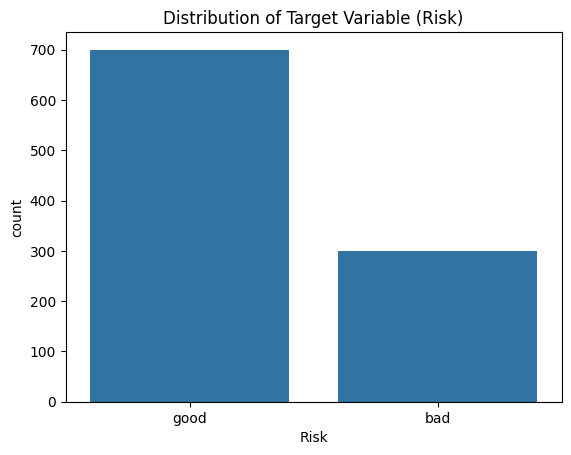

In [39]:
print(data_frame['Risk'].value_counts())
print(data_frame['Risk'].value_counts(normalize=True))
sns.countplot(x='Risk', data=data_frame);
plt.title('Distribution of Target Variable (Risk)');
plt.show()

**Observations**: The target classes are imbalanced. There are 700 good cases (70%) and 300 bad cases (30%). If we used a simple model that always predicts “good,” it would get 70% accuracy but would not identify any risky borrowers. To address this, we will:

* use a stratified train/test split to make sure both sets keep the 70/30 ratio,
* evaluate models using precision, recall, F1-score, and ROC AUC instead of relying only on accuracy,
* consider class weighting when tuning hyperparameters.

###Distribution of numerical features
Histograms show the shape (skewness) of each of the numerical variables. The boxplots grouped by Risk show both the potential outliers (the points beyond the whiskers) and whether the variable differs between the good and bad borrowers.

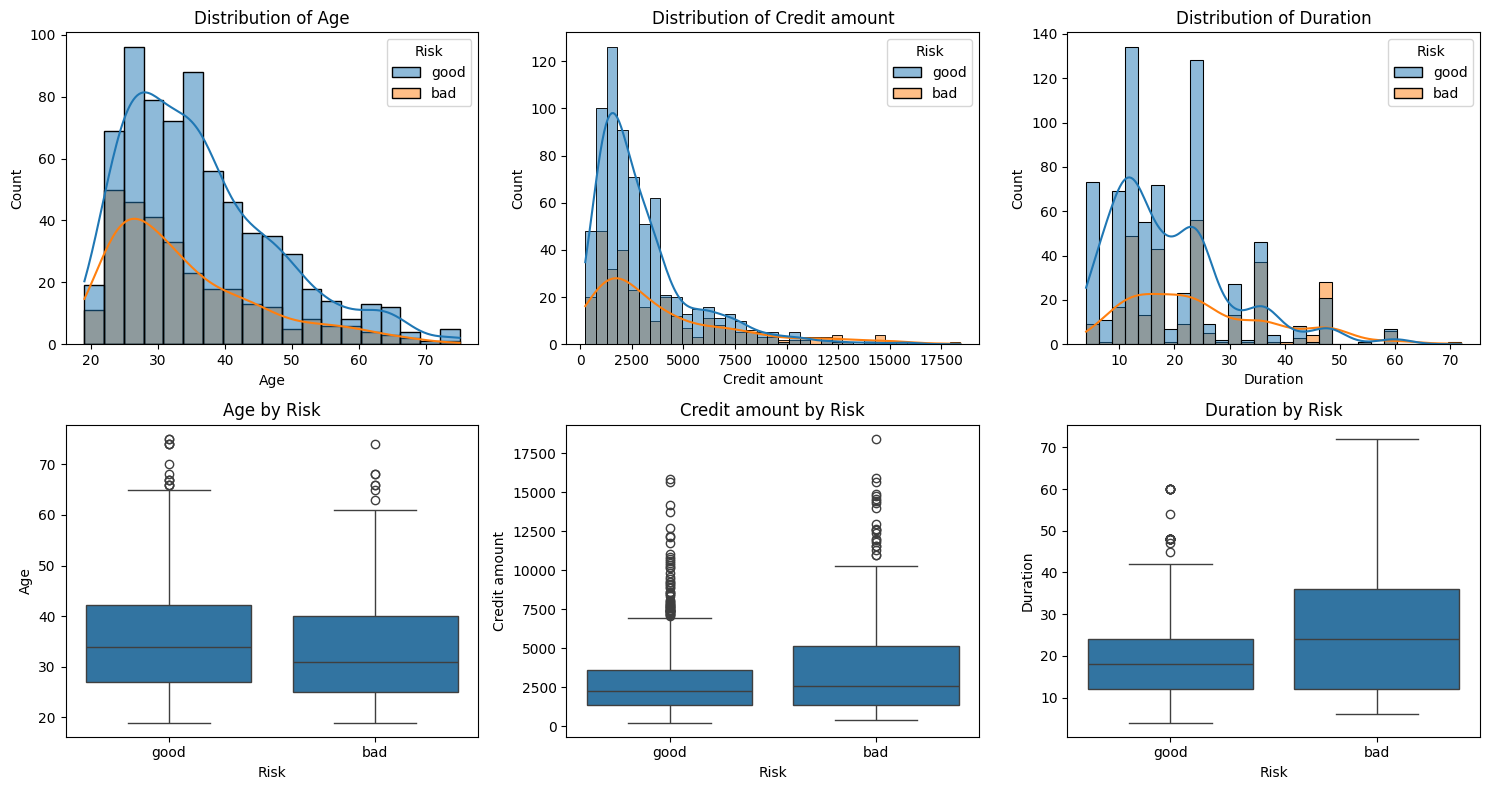

            Age  Credit amount   Duration
Risk                                     
bad   33.963333    3938.126667  24.860000
good  36.224286    2985.457143  19.207143


In [40]:
# Create a figure containing 2 rows and 3 columns of subplots.
fig, ax = plt.subplots(2, 3, figsize=(15, 8))

# Loop through each numerical column.
# Create a histogram to visualise the distribution of the current numerical column.
for index, category in enumerate(numerical_cols):
  sns.histplot(data_frame, x=category, hue='Risk', kde=True, ax=ax[0,index]);
  ax[0, index].set_title(f'Distribution of {category}')
  sns.boxplot(data_frame, x='Risk', y=category, ax=ax[1, index]);
  ax[1, index].set_title(f'{category} by Risk')

# Adjust spacing between subplots, display all plots, and calculate the mean of
# each numerical column, grouped by Risk category.
plt.tight_layout();
plt.show()
print(data_frame.groupby('Risk')[numerical_cols].mean())

**Observations:**
- All three numerical features are **right-skewed** (Credit amount most strongly), and the boxplots show many points beyond the upper whiskers – potential outliers that will be treated soon.
- Bad borrowers take larger loans (mean ≈ 3,938 DM vs 2,986 DM for good borrowers) and longer durations (≈ 24.9 vs 19.2 months), suggesting larger and longer loans carry more risk.
- Bad borrowers are slightly younger on average (≈ 34.0 vs 36.2 years).

###Categorical features vs. Risk

For each categorical feature, we plot the proportion of good and bad borrowers in each category. This shows which categories are associated with higher default rates and are therefore likely useful predictors. Missing values are shown as a separate group (with dropna=False) to see if the missingness itself is informative.



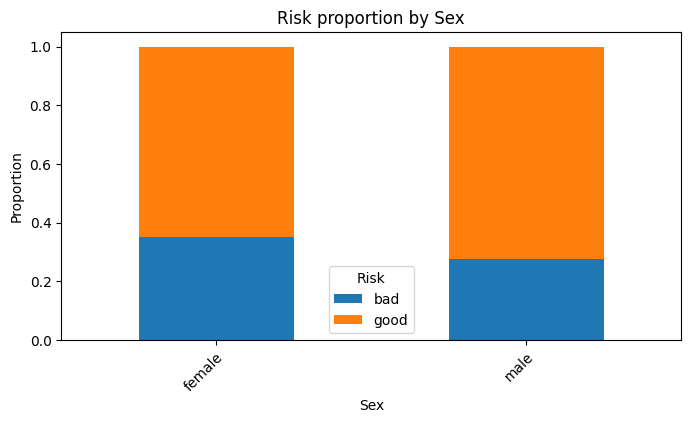

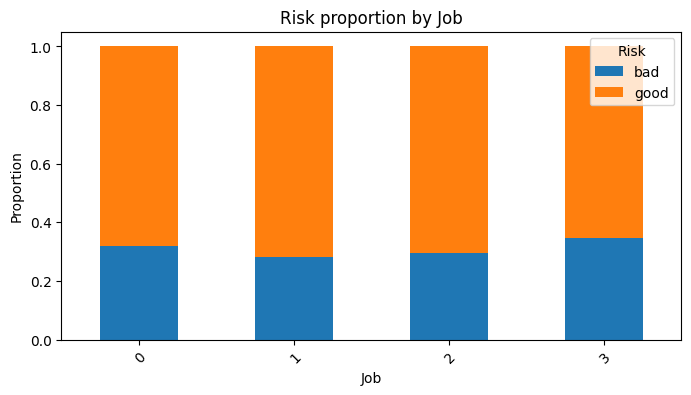

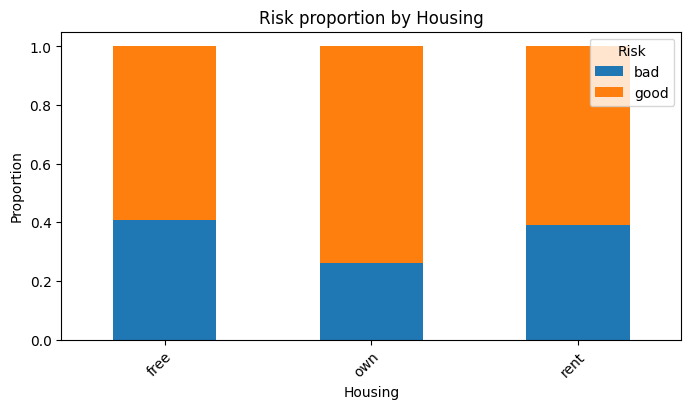

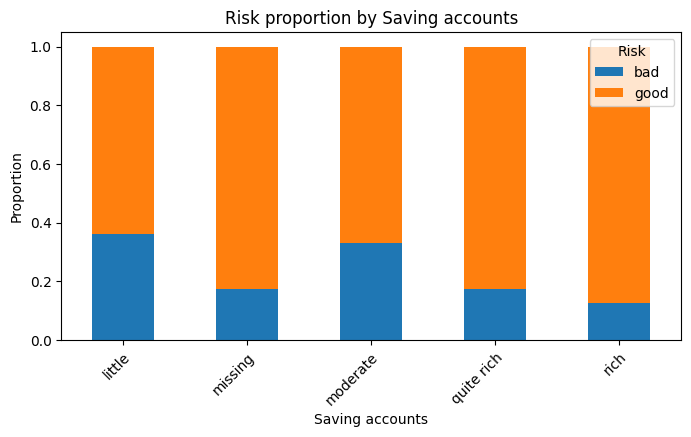

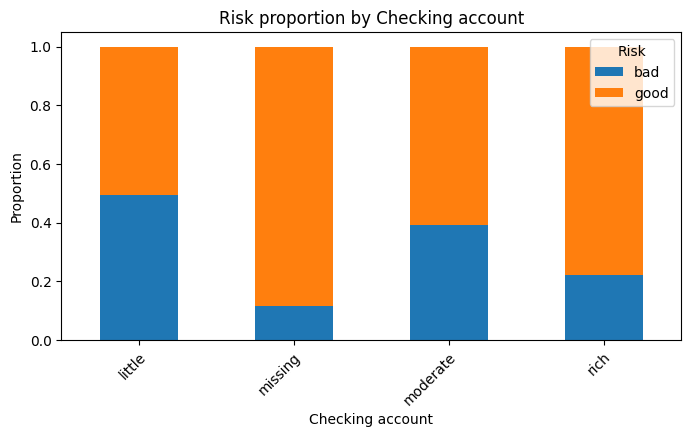

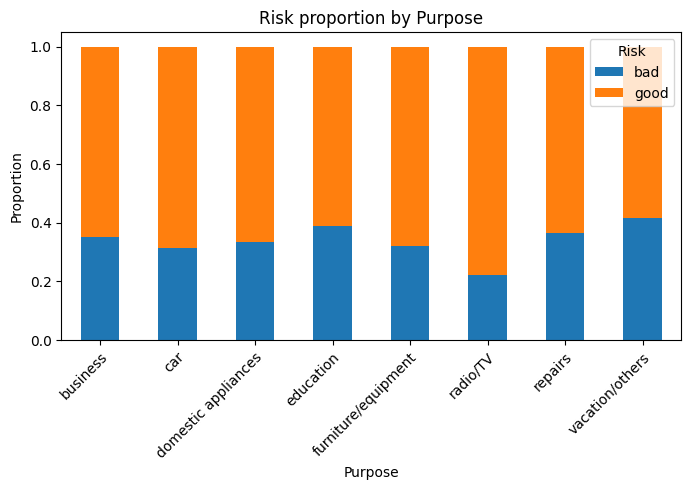

In [41]:
for category in categorical_cols:
      risk_proportion = pd.crosstab(
        data_frame[category].fillna('missing'),
        data_frame['Risk'],
        normalize='index'
    )

      risk_proportion.plot(
        kind='bar',
        stacked=True,
        figsize=(8, 4),
        title=f'Risk proportion by {category}'
    )


      plt.ylabel('Proportion')
      plt.xticks(rotation=45, ha='right', rotation_mode='anchor')
      plt.show()

###Observations (bad-risk rate per category):

* Checking account status stands out: 'little' has a 49% bad rate, 'moderate' is at 39%, 'rich' at 22%, and missing at 12%. Missing values mean there is no checking account, so we should keep them.

* Savings accounts: “little” has a 36% bad rate, “rich” is at 12%, and missing is 17%. More savings means lower risk.

* Housing: owners have a 26% bad rate, which is lower than renters at 39% or people living for free at 41%.

* Purpose: education loans have a 39% bad rate and business loans are at 35%, making them riskier. Radio/TV loans are safest at 22%.

* Sex: female applicants have a 35% bad rate, which is higher than the 28% for male applicants.

* Job: default rates are similar across skill levels, ranging from 28% to 34%, so this may not be a strong predictor.



###Correlation between numerical features
Now we use a correlation heatmap to check for strong linear relationships between numerical features. Highly correlated features (multicollinearity) can make logistic regression coefficients unstable and harder to interpret.

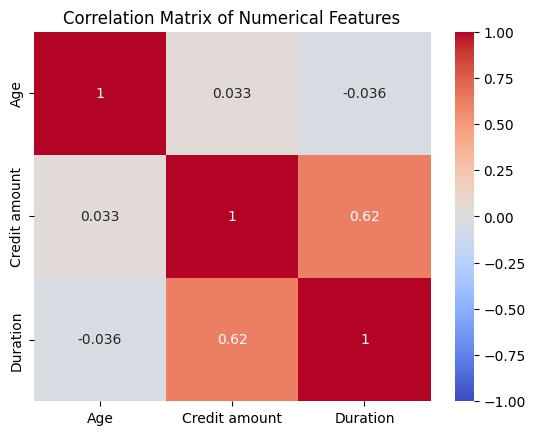

In [42]:
sns.heatmap(data_frame[numerical_cols].corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix of Numerical Features');
plt.show()

### Observations:
Credit amount and Duration show a moderate positive correlation (r ≈ 0.62), meaning larger loans are usually repaid over longer periods. This correlation is not strong enough to remove either feature, but it should be considered when interpreting coefficients. Age is basically uncorrelated with both (r ≈ 0.03 and −0.04).

### Summary of EDA findings and implications for modelling
1. The dataset includes 1,000 applicants and 9 features: 3 numerical, 5 nominal categorical, and an ordinal feature called `Job`.

2. There are missing values in `Saving accounts` (183) and `Checking account` (394). Because missingness is linked to low risk, these will be treated as a separate "unknown" category.

3. Some numerical features are skewed and have outliers, especially `Credit amount`. IQR-based capping will be used to address this.

4. The target variable is imbalanced (70/30), so a stratified split, class weighting, and additional metrics beyond accuracy will be used.

5. The most promising predictors are checking account status, savings, duration, credit amount, housing, and purpose.

## 2. Handling Missing Values and Outliers
Our goal here is to handle the missing values so that the data can be useful when we introduce the machine learning algorithms like Logistic Regression, SVM and Naive Bayes in scikit-learn. Also, because outliers can distort feature scaling as we've seen earlier, and pull model parameters towards a few extreme point, we will also handle them.

### Identifying missing values
first, we will count missing values per column and express them as a percentage of the dataset, to decide a better option, whether it will be imputation or removal.

In [43]:
missing = pd.DataFrame({'Missing count': data_frame.isna().sum(), 'Missing %': (data_frame.isna().mean() * 100).round(1)})

display(missing[missing['Missing count'] > 0])

print('Rows with at least one missing value:', data_frame.isna().any(axis=1).sum())
print('Rows missing both:', (data_frame['Saving accounts'].isna() & data_frame['Checking account'].isna()).sum())

,Missing count,Missing %
Saving accounts,183,18.3
Checking account,394,39.4


Rows with at least one missing value: 478
Rows missing both: 99


### Observations:
* The Saving accounts field is missing in 183 rows (18.3%), and the Checking account field is missing in 394 rows (39.4%). There are 99 rows where both are missing.
* A total of 478 rows (47.8%) have at least one missing value. Removing these incomplete rows would mean losing nearly half of the dataset.
* All the other columns have complete data.

###Choosing and applying a missing-value strategy

There are three options we can consider for managing missing values:

1. Drop rows with missing values. Doing this would remove about 48% of the data. Since we only have 1,000 rows, this would leave us with much less data to train our model.

2. We could fill in missing values with the most common category, "little." But this would be misleading. From our EDA, we found that applicants missing checking account info have a 12% bad rate, while those in the "little" category have a 49% bad rate. So, using "little" for missing values would not reflect the true risk for these applicants.

3. Our next option is to treat missing values as a separate category, "unknown". This way, we keep all 1,000 rows and retain any information missing values might tell us about an applicant's credit risk.

Of the three options, the third is best. So, we chose to treat missing values as a separate category, "unknown."

In the original German Credit dataset, missing values in these columns usually mean the applicant does not have that account or the information was not recorded. That means missing values themselves might help predict credit risk.

Instead of dropping this information or imputing it, we will use "unknown" for missing values. Later, we will one-hot encode this category along with the others.

This method also uses a fixed value instead of something learned from the data. That means we can apply it before splitting into train and test sets without causing data leakage.

In [44]:
data_frame[['Saving accounts', 'Checking account']] = data_frame[['Saving accounts', 'Checking account']].fillna('unknown')
print(data_frame.isna().sum())
print(data_frame['Checking account'].value_counts())

Age                 0
Sex                 0
Job                 0
Housing             0
Saving accounts     0
Checking account    0
Credit amount       0
Duration            0
Purpose             0
Risk                0
dtype: int64
Checking account
unknown     394
little      274
moderate    269
rich         63
Name: count, dtype: int64


### Observation:
From the result of the output, we can see that no missing values remain, and all 1,000 rows are kept.

`Checking account` now has four categories (little, moderate, rich, unknown) and `Saving accounts` has five (little, moderate, quite rich, rich, unknown).

### Detecting outliers with IQR method

The Interquartile Range (IQR) method is a reliable way to identify outliers in a distribution.

* IQR = Q3 − Q1 (the range of the middle 50% of the data)
* Lower bound = Q1 − 1.5 × IQR
* Upper bound = Q3 + 1.5 × IQR
* If a value falls outside these limits, it is considered an outlier.

Here, we use the IQR method instead of the z-score method because our EDA shows the data is skewed. The z-score works best with data that is close to a normal distribution. Boxplots also help us spot outliers visually, since points beyond the whiskers match the IQR outliers.



,Feature,Lower bound,Upper bound,Outliers,% of data,Bad rate among outliers (%)
0,Age,4.500,64.500,23,2.3,26.1
1,Credit amount,-2544.625,7882.375,72,7.2,54.2
2,Duration,-6.000,42.000,70,7.0,57.1


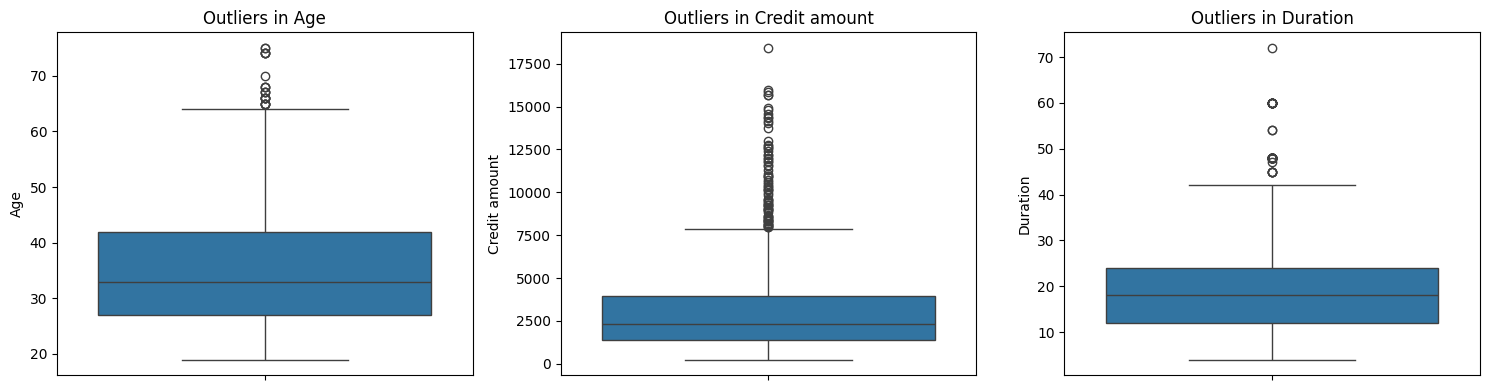

In [45]:
#create the function
def iqr_bounds(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

summary = []

for category in numerical_cols:
    lower_bound, upper_bound = iqr_bounds(data_frame[category])

    outlier_mask = (data_frame[category] < lower_bound) | (data_frame[category] > upper_bound)

    summary.append({
        'Feature': category,
        'Lower bound': lower_bound,
        'Upper bound': upper_bound,
        'Outliers': outlier_mask.sum(),
        '% of data': round(outlier_mask.mean() * 100, 1),
        'Bad rate among outliers (%)': round(
            (data_frame.loc[outlier_mask, 'Risk'] == 'bad').mean() * 100, 1
        )
    })

display(pd.DataFrame(summary))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for index, category in enumerate(numerical_cols):
    sns.boxplot(y=data_frame[category], ax=axes[index])
    axes[index].set_title(f'Outliers in {category}')

plt.tight_layout()
plt.show()

Observations:

Our IQR analysis found outliers in all three numerical features. For Age, the upper limit is 64.5 years, with 23 outliers (2.3% of the data) and a bad rate of 26%. For Credit amount, the upper limit is about 7,882 DM, with 72 outliers (7.2%) and a bad rate of 54%. For Duration, the upper limit is 42 months, with 70 outliers (7.0%) and a bad rate of 57%.

All the outliers are on the upper end of the distributions, and there are no outliers on the lower end. This matches the right-skewed distributions seen during the EDA.

These outliers seem to be real cases, not data-entry mistakes. For example, a 75-year-old applicant, an 18,424 DM loan, or a 72-month repayment period are all possible in practice.

The outlier analysis also shows a possible link between loan features and credit risk. Applicants with much larger credit amounts and longer repayment periods have much higher bad rates (54–57%) than the overall bad rate of 30%. This means these cases may provide useful information for predicting credit risk.

So, we will keep these outliers rather than remove them, and cap them instead.

###IQR capping (Outlier treatment strategy)
IQR capping helps us in several ways:

* It keeps every applicant in the dataset,
* It preserves the ordering ("this is a very large loan") and limits the extreme influence of a few points on the mean and standard deviation used by `StandardScaler`. It also reduces their impact on the weights of distance-based and gradient-based models like SVM and Logistic Regression.


## 3. Train/Test Split, Categorical Encoding and Feature Scaling
Machine learning models work best when their input data is all numerical and on similar scales. They should also be tested on data they have not seen before.

To avoid data leakage, we first split the data. Then, any preprocessing that learns from the data, like capping values, scaling, or encoding categories, is done using only the training set and later applied to the test set.



### Encode the target and split the data
* The target risk is binary. This means 1 is bad (default) and 0 is good. Since our primary objective is to find defaults, 'bad' is the positive class. We'll measure precision, recall, and F1 for detecting defaults.
* We will split the data into an 80/20,that means 800 rows as the training set and 200 rows as the test set. We use the training set to fit the model and tune hyperparameters via cross-validation. The test set is held back for the final evaluation.
* Using stratify=y maintains the same 70/30 good/bad split in both the training and test sets. Without it, we could end up with a completely random split and have too many or too few defaulters in the test set, which would be very misleading.
* Setting random_state=42 ensures we can reproduce the split.

In [46]:
from sklearn.model_selection import train_test_split

data_frame['Risk'] = (data_frame['Risk'] == 'bad').astype(int)

X, y = data_frame.drop(columns='Risk'), data_frame['Risk']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print('Training set:', X_train.shape, ' Test set:', X_test.shape)
print('\nClass proportions – training set:\n', y_train.value_counts(normalize=True))
print('\nClass proportions – test set:\n', y_test.value_counts(normalize=True))

Training set: (800, 9)  Test set: (200, 9)

Class proportions – training set:
 Risk
0    0.7
1    0.3
Name: proportion, dtype: float64

Class proportions – test set:
 Risk
0    0.7
1    0.3
Name: proportion, dtype: float64


### Observation

The training set has 800 applicants (560 good, 240 bad) and the test set has 200 (140 good, 60 bad). Both keep exactly the 70% / 30% class ratio of the full dataset. This confirms that the stratified split worked.

### Applying IQR capping (using training-set bounds only)
Now that the data is split, we compute the IQR bounds from `X_train` and clip both `X_train` and `X_test` to those bounds.

Capping bounds (from training set): {'Age': (6.0, 62.0), 'Credit amount': (-2517.0, 7803.0), 'Duration': (-6.0, 42.0)}


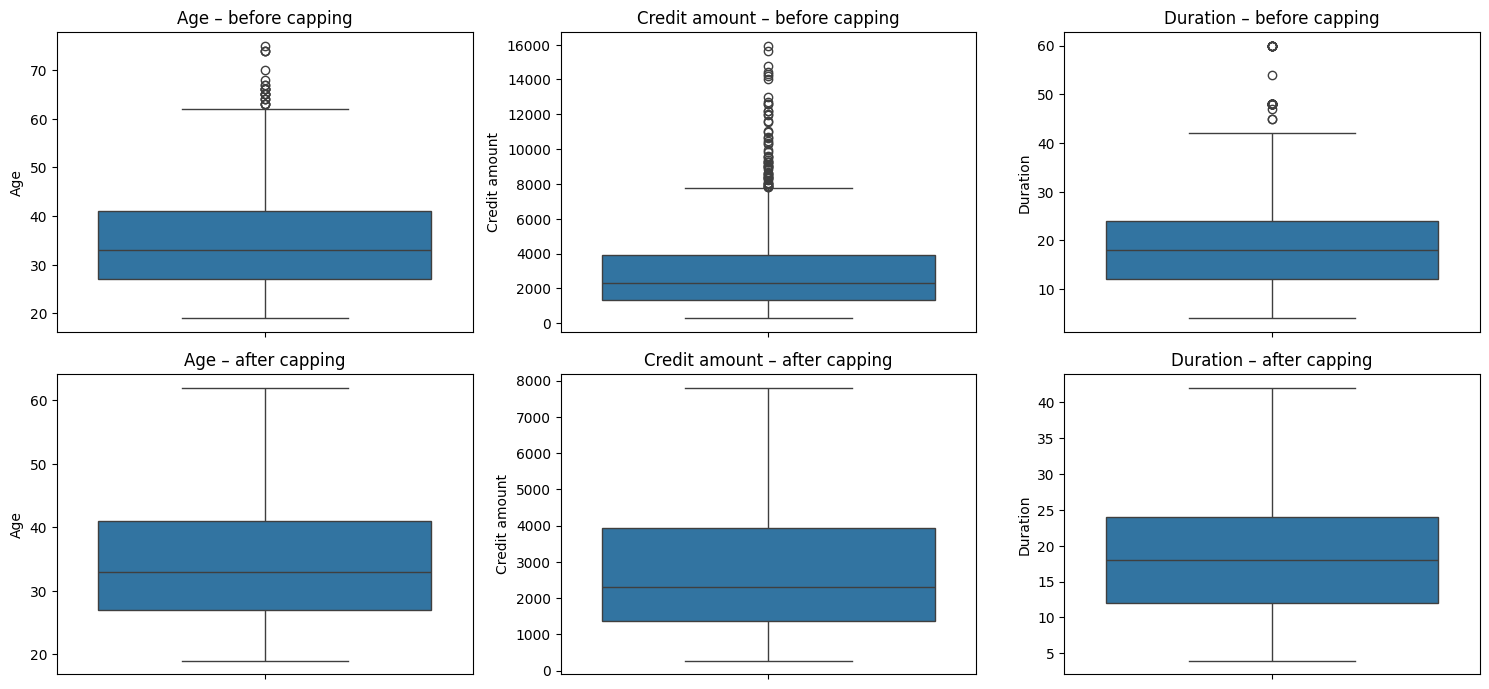

In [47]:
X_train, X_test = X_train.copy(), X_test.copy()

X_train_before = X_train.copy()

bounds = {category: iqr_bounds(X_train[category]) for category in numerical_cols}


for category, (lower_bound, upper_bound) in bounds.items():
    X_train[category] = X_train[category].clip(lower_bound, upper_bound)
    X_test[category]  = X_test[category].clip(lower_bound, upper_bound)

print(
    'Capping bounds (from training set):',
     {category:
      (round(lower_bound, 1),
       round(upper_bound, 1)) for category,
        (lower_bound, upper_bound) in bounds.items()
      })

fig, axes = plt.subplots(2, 3, figsize=(15, 7))

for index, category in enumerate(numerical_cols):

    sns.boxplot(y=X_train_before[category], ax=axes[0, index]);

    axes[0, index].set_title(f'{category} – before capping')

    sns.boxplot(y=X_train[category], ax=axes[1, index]);

    axes[1, index].set_title(f'{category} – after capping')


plt.tight_layout(); plt.show()


### Observation

From the result, we can observe that the boxplots no longer show points beyond the whiskers after capping.

### Encode the categorical variables
we have to convert the categorical text values to numbers. This is because models such as logistic regression and SVM work with numbers. The encoding is chosen according to the nature of each variable.

To encode categorical features, I considered the feature type and whether the categories had a natural order.
* Sex, Housing, and Purpose: These are nominal categorical features, so their categories have no natural order. I'll use One-Hot Encoding instead of label encoding. For example, if we assign car = 0, education = 1, and business = 2, it would create a ranking that isn't actually present in the data.

*  Saving accounts and Checking account: These features have ordered categories (little, moderate, rich), but they also include an unknown category that doesn't fit into this order. I'll use One-Hot Encoding so the model can learn a separate relationship for each category and credit risk. This matters because our EDA showed the unknown category has a unique low-risk signal.

* Job is already a numeric variable with values ranging from 0 to 3. 0 is unskilled non-resident employment and 3 is highly skilled employment. As they are ordered we'll leave them as they are and scale them in with the other numeric variables.



I’ll set up the One-Hot Encoder with these two options:
* 1. drop='first': This option will drop the first category of each feature making it the reference category.
* 2. handle_unknown='ignore': the pipeline will not fail if it encounters a new category in the data that wasn't seen during training.


###Scaling numerical features

Age (19–75), Credit amount (250–18,424), and Duration (4–72) all have very different ranges. If we do not scale them:

* SVM would focus mostly on Credit amount, since it uses distances between data points.
* Gradient descent, which we use in our custom Logistic Regression, would either converge slowly or not at all.
* Regularisation, which penalizes coefficients in Logistic Regression and SVM, would not treat all features equally.


We use StandardScaler, which changes each feature so it has a mean of 0 and a standard deviation of 1: z = (x − mean) / std. We chose this over MinMaxScaler because MinMax depends on the smallest and largest values, making it sensitive to outliers. Standardised features also work better with gradient descent and regularised linear models.

To stop any data leakage we calculate the scaler's mean and standard deviation using only the training set (fit_transform on X_train). We then use those values to transform the test set (transform only). The test set doesn't get used in any of the preprocessing at all, just as you'd expect with real new applicants.

We combine both steps using a scikit-learn ColumnTransformer which applies the appropriate transformation to each group of columns. We'll be using the same object in the cross-validation pipelines so scaling will be re-fitted in each fold.

In [48]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numerical_features = ['Age', 'Credit amount', 'Duration', 'Job']
categorical_features = ['Sex', 'Housing', 'Saving accounts', 'Checking account', 'Purpose']

pre = ColumnTransformer([
    ('numerical', StandardScaler(), numerical_features),
    ('categorical', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), categorical_features)])

X_train_p = pre.fit_transform(X_train)

# apply the transformation to the test data
X_test_p  = pre.transform(X_test)

feature_names = pre.get_feature_names_out()

print('Processed training set:', X_train_p.shape, ' Processed test set:', X_test_p.shape)
print('\nFeatures after encoding:\n', list(feature_names))
display(pd.DataFrame(X_train_p, columns=feature_names).head())

Processed training set: (800, 21)  Processed test set: (200, 21)

Features after encoding:
 ['numerical__Age', 'numerical__Credit amount', 'numerical__Duration', 'numerical__Job', 'categorical__Sex_male', 'categorical__Housing_own', 'categorical__Housing_rent', 'categorical__Saving accounts_moderate', 'categorical__Saving accounts_quite rich', 'categorical__Saving accounts_rich', 'categorical__Saving accounts_unknown', 'categorical__Checking account_moderate', 'categorical__Checking account_rich', 'categorical__Checking account_unknown', 'categorical__Purpose_car', 'categorical__Purpose_domestic appliances', 'categorical__Purpose_education', 'categorical__Purpose_furniture/equipment', 'categorical__Purpose_radio/TV', 'categorical__Purpose_repairs', 'categorical__Purpose_vacation/others']


,numerical__Age,numerical__Credit amount,numerical__Duration,numerical__Job,categorical__Sex_male,categorical__Housing_own,categorical__Housing_rent,categorical__Saving accounts_moderate,categorical__Saving accounts_quite rich,categorical__Saving accounts_rich,...,categorical__Checking account_moderate,categorical__Checking account_rich,categorical__Checking account_unknown,categorical__Purpose_car,categorical__Purpose_domestic appliances,categorical__Purpose_education,categorical__Purpose_furniture/equipment,categorical__Purpose_radio/TV,categorical__Purpose_repairs,categorical__Purpose_vacation/others
0,1.113072,2.220412,1.494889,0.145975,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.265824,-1.022393,-0.782495,0.145975,1.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,-0.675563,1.093608,1.494889,0.145975,1.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,-0.581424,0.453758,1.494889,-2.968168,0.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,-1.052117,2.220412,2.064234,0.145975,0.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


In [49]:
num_feature_count = len(numerical_features)

check = pd.DataFrame({
    'Train mean': X_train_p[:, :num_feature_count].mean(axis=0),
    'Train std': X_train_p[:, :num_feature_count].std(axis=0),
    'Test mean': X_test_p[:, :num_feature_count].mean(axis=0),
    'Test std': X_test_p[:, :num_feature_count].std(axis=0)
}, index=numerical_features).round(3)

display(check)

,Train mean,Train std,Test mean,Test std
Age,-0.0,1.0,0.095,1.126
Credit amount,-0.0,1.0,0.080,1.031
Duration,0.0,1.0,0.029,1.033
Job,-0.0,1.0,-0.018,1.083


### Observations:

* Encoding turned the 9 original features into 21 numerical features ready for the model. These include 4 scaled numerical features (Age, Credit amount, Duration, Job) and 17 one-hot columns (Sex 1, Housing 2, Saving accounts 4, Checking account 3, Purpose 7). Each one-hot group has one fewer column than its number of categories because drop='first' was used.
* In the training set, the scaled numerical features have a mean of 0 and a standard deviation of 1, as expected.
* In the test set, the means and standard deviations are close to 0 and 1, but not exactly. This shows there was no data leakage. The test set was transformed using the training set’s statistics, not its own.

Preprocessing pipeline summary

1. Missing values are filled with the constant "unknown." Since no statistics are learned, this step is safe to do before splitting.
2. The data is split in a stratified 80/20 ratio, resulting in 800 training rows and 200 test rows.
3. IQR capping is performed by learning bounds from the training data and applying them to both the training and test sets.
4. Nominal features are one-hot encoded with the first category dropped. The Job feature is kept as an ordinal numeric variable.
5. StandardScaler is fitted on the training data and then applied to both the training and test sets.

The data is now ready for modeling.  We’ll use X_train_p and y_train for training and tuning, and X_test_p and y_test for the final evaluation.

## 4. Logistic regression


 How it works:

1. Linear combination. For each applicant, the model takes their feature vector $x$ and calculates a weighted sum, then adds a bias (intercept):
$$z = w^T x + b$$

2. Sigmoid function. The sigmoid turns $z$ into a probability between 0 and 1. This number shows how likely it is that the applicant is a bad credit risk:
$$\hat{p} = \sigma(z) = \frac{1}{1 + e^{-z}}$$

3. Cost function – Binary Cross-Entropy (log loss). This measures how close the predicted probabilities are to the actual labels. Wrong predictions made with high confidence get a bigger penalty. Adding an optional L2 penalty helps prevent the weights from getting too large, which can reduce overfitting:
$$J(w,b) = -\frac{1}{n}\sum_{i=1}^{n}\Big[y_i\log(\hat{p}_i) + (1-y_i)\log(1-\hat{p}_i)\Big] + \frac{\lambda}{2n}\sum_{j} w_j^2$$

4. Gradients. The partial derivatives of the cost show which way each parameter should move to make the cost smaller. In vectorised form:
$$\frac{\partial J}{\partial w} = \frac{1}{n}X^T(\hat{p} - y) + \frac{\lambda}{n}w \qquad \frac{\partial J}{\partial b} = \frac{1}{n}\sum_{i=1}^{n}(\hat{p}_i - y_i)$$

5. Gradient descent update. The parameters are updated by taking small steps, set by the learning rate $\alpha$, in the opposite direction of the gradient. This is done over and over:
$$w \leftarrow w - \alpha\frac{\partial J}{\partial w} \qquad b \leftarrow b - \alpha\frac{\partial J}{\partial b}$$

6. Stopping condition. Training ends when the cost gets better by less than a small amount between steps, meaning the model has converged. It can also stop if it reaches the maximum number of steps.

7. Prediction. If $\hat{p} \geq 0.5$, the applicant is classified as bad (1). If not, they are classified as good (0).

### Visualising the sigmoid function
The sigmoid maps any real number to the range (0, 1). Large positive $z$ gives a probability near 1 (high default risk), large negative $z$ gives a probability near 0, and $z = 0$ gives exactly 0.5, which is decision threshold.

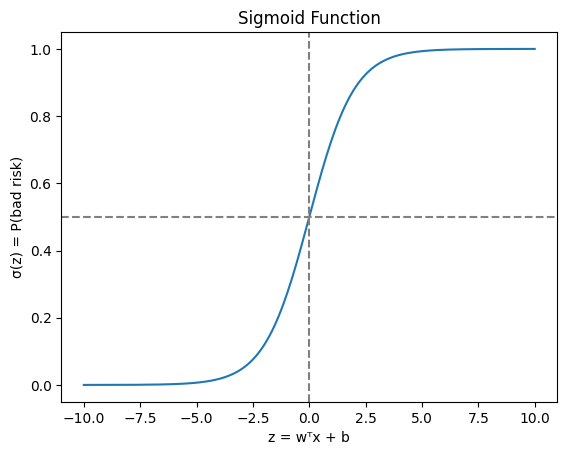

In [50]:
z = np.linspace(-10, 10, 200)
plt.plot(z, 1 / (1 + np.exp(-z)))
plt.axhline(0.5, ls='--', color ='grey'); plt.axvline(0, ls='--', color ='grey')
plt.xlabel('z = wᵀx + b');
plt.ylabel('σ(z) = P(bad risk)');
plt.title('Sigmoid Function');
plt.show()

### Implementing the LogisticRegressionScratch class

This class uses the same interface as scikit-learn models, with methods like fit, predict_proba, and predict. That means we can evaluate it just like a scikit-learn model.

* The gradients are calculated for all 800 training samples and 21 features at the same time using matrix multiplication (X.T @ error), without looping over samples in Python. This approach is faster and reduces the chance of mistakes.

* The intercept b, also called the bias term, is learned separately and is not regularised. This matches the standard approach and how scikit-learn handles it.

* The class keeps track of the cost history, so you can plot it and check if the model has converged.

In [51]:

class LogisticRegressionScratch:
    """Binary logistic regression trained with batch gradient descent (NumPy only)."""

    def __init__(self, learning_rate=0.5, n_iters=20000, l2=0.0, tol=1e-9, verbose=True):

        # Step size (alpha)
        self.learning_rate = learning_rate

        # Maximum number of training iterations
        self.n_iters = n_iters

        # L2 regularisation strength (lambda)
        self.l2 = l2

        # Stop training when the cost improvement falls below this tolerance
        self.tol = tol

        self.verbose = verbose

    @staticmethod
    def sigmoid(linear_output):
        # Clip values to prevent numerical overflow during exponentiation
        linear_output = np.clip(linear_output, -500, 500)

        return 1.0 / (1.0 + np.exp(-linear_output))

    def _compute_cost(self, X, y):
        num_samples = len(y)

        # Calculate predicted probabilities
        predicted_probabilities = self.sigmoid(X @ self.weights + self.bias)

        epsilon = 1e-12

        # Calculate binary cross-entropy loss
        binary_cross_entropy = -np.mean(
            y * np.log(predicted_probabilities + epsilon)
            + (1 - y) * np.log(1 - predicted_probabilities + epsilon)
        )

        # Add L2 regularisation penalty
        return binary_cross_entropy + (self.l2 / (2 * num_samples)) * np.sum(self.weights ** 2)

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)

        num_samples, num_features = X.shape

        self.weights = np.zeros(num_features)
        self.bias = 0.0

        self.cost_history = [self._compute_cost(X, y)]
        self.converged_ = False

        # Perform batch gradient descent
        for iteration in range(1, self.n_iters + 1):

            predicted_probabilities = self.sigmoid(X @ self.weights + self.bias)

            prediction_errors = predicted_probabilities - y

            # Calculate gradients for weights and bias
            weight_gradient = (
                (X.T @ prediction_errors) / num_samples
                + (self.l2 / num_samples) * self.weights
            )

            bias_gradient = np.mean(prediction_errors)

            self.weights -= self.learning_rate * weight_gradient
            self.bias -= self.learning_rate * bias_gradient

            self.cost_history.append(self._compute_cost(X, y))

            # Check whether the model has converged
            if abs(self.cost_history[-2] - self.cost_history[-1]) < self.tol:
                self.converged_ = True
                break

        self.n_iter_ = iteration

        if self.verbose:
            training_status = (
                'Converged' if self.converged_
                else 'Stopped (max iterations reached)'
            )

            print(
                f'{training_status} after {self.n_iter_} iterations '
                f'| final cost = {self.cost_history[-1]:.6f}'
            )

        return self

    def predict_proba(self, X):
        # Return the predicted probability of the positive class
        X = np.asarray(X, dtype=float)
        return self.sigmoid(X @ self.weights + self.bias)

    def predict(self, X, threshold=0.5):
        # Convert predicted probabilities into binary class predictions
        return (self.predict_proba(X) >= threshold).astype(int)


### Training the model and checking convergence

We train the model using the preprocessed training set (X_train_p, y_train) with the following settings:

* learning rate α = 0.5, which is high enough for quick progress but still stable since the features are standardised (see 4.5);
* λ = 1.0, which applies mild L2 regularisation (chosen to match scikit-learn’s default C = 1.0, see 4.6);
* tolerance = 1e-9 and up to 20,000 iterations. This gives the weights of rare categories (for example, Purpose_vacation/others, which make up only about 1% of applicants) enough time to fully converge, even though they receive small gradients and learn slowly.

If gradient descent works as expected, the cost will go down with each iteration and eventually level off.

Converged after 2382 iterations | final cost = 0.509037


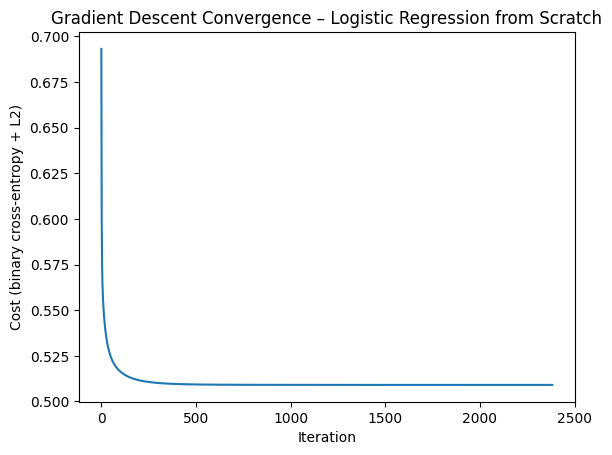

Cost always decreased: True
Bias (intercept): 0.3684


In [52]:
scratch = LogisticRegressionScratch(
    learning_rate=0.5,
    n_iters=20000,
    l2=1.0,
    tol=1e-9
)

scratch.fit(X_train_p, y_train.values)

plt.plot(scratch.cost_history)
plt.xlabel('Iteration')
plt.ylabel('Cost (binary cross-entropy + L2)')
plt.title('Gradient Descent Convergence – Logistic Regression from Scratch')
plt.show()

print('Cost always decreased:', np.all(np.diff(scratch.cost_history) <= 1e-12))
print('Bias (intercept):', round(scratch.bias, 4))

### Observations:

The model finished training after 2382 iterations, reaching a final cost of 0.509037. The cost began at 0.693 (which is ln 2, the value when all weights are zero and predictions are 0.5), dropped quickly at first, then leveled off, and decreased with each iteration. This shows that the gradients are correct and the learning rate works well.

### Effect of the learning rate

The learning rate sets how big each step is during gradient descent.

* If the learning rate is too small, the model will converge very slowly and need many iterations.
* If the learning rate is too large, the updates can overshoot the minimum, causing the cost to oscillate or even diverge.
* With a well-chosen learning rate, the model converges quickly and smoothly.

Next, we train the model for 2,000 iterations using different learning rates and then compare the cost curves.

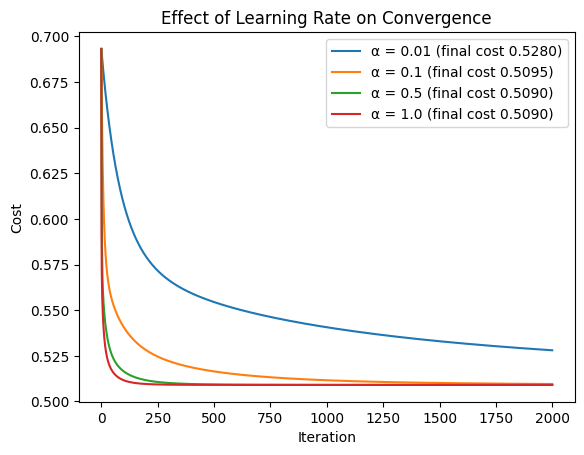

In [53]:
for learning_rate in [0.01, 0.1, 0.5, 1.0]:

    model = LogisticRegressionScratch(
        learning_rate=learning_rate,
        n_iters=2000,
        l2=1.0,
        tol=0,
        verbose=False
    )

    model.fit(X_train_p, y_train.values)

    plt.plot(
        model.cost_history,
        label=f'α = {learning_rate} (final cost {model.cost_history[-1]:.4f})'
    )

plt.xlabel('Iteration')
plt.ylabel('Cost')
plt.title('Effect of Learning Rate on Convergence')
plt.legend()
plt.show()

###Observations:

When α is set to 0.01, the cost drops very slowly and is still far from the minimum after 2,000 iterations. Using larger learning rates like 0.5 or 1.0 helps reach a low cost much faster. Since the features were standardised in the Split, encode and scale step, the cost surface is well-conditioned, so even fairly large learning rates stay stable. This example shows why feature scaling is important for gradient descent.

### Validate against scikit-learn

Now, we'll check our implementation by training scikit-learn's LogisticRegression on the same data and then comparing the weights, the intercept and the test set performance.

To make a fair comparison we need both models to be minimising the same objective. scikit-learn's L2 regularised objective is (1/2)|w|^2 + C*sum_i(loss_i). If we divide that by Cn then it's exactly our cost function when lambda = 1/C. That means our lambda of 1.0 is equivalent to scikit-learn's default C of 1.0. We've also set scikit-learn's tolerance to tol=1e-8 so both models are being solved to the same high precision.



,From scratch,scikit-learn
Test accuracy,0.7300,0.7300
Test ROC AUC,0.7552,0.7551
Intercept (bias),0.3684,0.3724


,From scratch,scikit-learn,Abs difference
numerical__Age,-0.0400,-0.0400,0.0001
numerical__Credit amount,-0.0805,-0.0804,0.0000
numerical__Duration,0.5324,0.5323,0.0001
numerical__Job,0.0011,0.0011,0.0000
categorical__Sex_male,-0.4093,-0.4096,0.0004
categorical__Housing_own,-0.2267,-0.2282,0.0015
categorical__Housing_rent,0.2640,0.2624,0.0017
categorical__Saving accounts_moderate,-0.0379,-0.0378,0.0001
categorical__Saving accounts_quite rich,-0.4710,-0.4711,0.0001
categorical__Saving accounts_rich,-0.9799,-0.9803,0.0004


Max absolute weight difference: 0.01613
Max difference in predicted probability: 0.00352
Test predictions in agreement: 100.0%


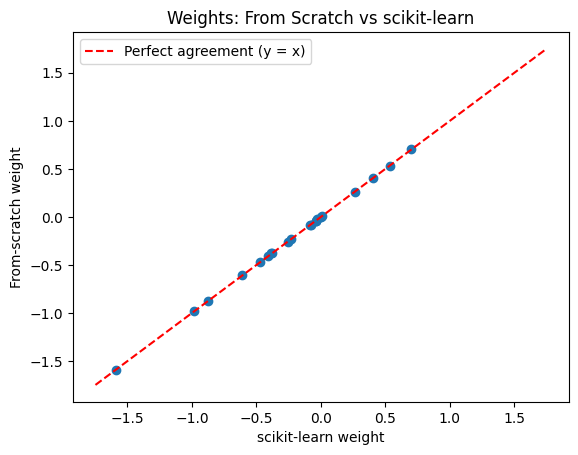

In [54]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score

# Train scikit-learn's logistic regression model
sklearn_model = LogisticRegression(C=1.0, max_iter=10000, tol=1e-8)
sklearn_model.fit(X_train_p, y_train)

# Generate predicted probabilities from both models
scratch_probabilities = scratch.predict_proba(X_test_p)
sklearn_probabilities = sklearn_model.predict_proba(X_test_p)[:, 1]

# Compare model performance and intercepts
summary = pd.DataFrame({
    'From scratch': [
        accuracy_score(y_test, scratch.predict(X_test_p)),
        roc_auc_score(y_test, scratch_probabilities),
        scratch.bias
    ],
    'scikit-learn': [
        accuracy_score(y_test, sklearn_model.predict(X_test_p)),
        roc_auc_score(y_test, sklearn_probabilities),
        sklearn_model.intercept_[0]
    ]
}, index=['Test accuracy', 'Test ROC AUC', 'Intercept (bias)']).round(4)

display(summary)

# Compare model weights
weights = pd.DataFrame({
    'From scratch': scratch.weights,
    'scikit-learn': sklearn_model.coef_[0]
}, index=feature_names)

weights['Abs difference'] = (
    weights['From scratch'] - weights['scikit-learn']
).abs()

display(weights.round(4))

# Check the maximum differences between the models
print(
    'Max absolute weight difference:',
    round(weights['Abs difference'].max(), 5)
)

print('Max difference in predicted probability:',
    round(np.abs(scratch_probabilities - sklearn_probabilities).max(), 5))

print(
    'Test predictions in agreement: {:.1f}%'.format(
        (scratch.predict(X_test_p) == sklearn_model.predict(X_test_p)).mean() * 100
    )
)

# Visualise how closely the model weights agree
plt.scatter(weights['scikit-learn'], weights['From scratch'])

limit = np.abs(weights[['From scratch', 'scikit-learn']].values).max() * 1.1

plt.plot(
    [-limit, limit],
    [-limit, limit],
    'r--',
    label='Perfect agreement (y = x)'
)

plt.xlabel('scikit-learn weight')
plt.ylabel('From-scratch weight')
plt.title('Weights: From Scratch vs scikit-learn')
plt.legend()
plt.show()

### Observations:
* Test accuracy: 0.7300 (from scratch) vs 0.7300 (scikit-learn); ROC AUC: 0.7552 vs 0.7551.
* The biggest difference between any two weights is just 0.01613, and every point on the scatter plot lies on the y = x line.
* 100% of the test predictions are exact matches, and the predicted probabilities differ by no more than 0.00352 (less than 0.4 percentage points).

The from-scratch version gives essentially the same results as scikit-learn. The only minor differences are due to the different optimisation algorithms (we're using plain gradient descent as opposed to scikit-learn's L-BFGS solver) and their respective stopping tolerances. It's not due to any error in the model.

## 5. Model training and hyperparameter tuning

We train three classification algorithms, each with a different way of separating good from bad borrowers:

| Model | How it works | Why it suits credit risk |
|---|---|---|
| **Logistic Regression** | Learns a linear weight per feature and converts the weighted sum into a probability with the sigmoid function (as implemented from scratch in the previous step) | Highly interpretable: each coefficient shows how a feature raises or lowers default risk, which matters in regulated lending |
| **Support Vector Machine (SVM)** | Finds the boundary (hyperplane) that separates the classes with the **widest margin**; with a kernel (e.g. RBF) it can learn non-linear boundaries | Can capture more complex relationships between features than a linear model |
| **Gaussian Naive Bayes** | Applies Bayes' theorem, assuming features are **independent** given the class and that each follows a normal distribution | Very fast and works with small datasets; a useful simple baseline |

###Why hyperparameter tuning is important

Parameters (e.g. the weights in a logistic regression) are learned from the data during the training process. Hyperparameters are the settings you choose prior to training which in turn affect how the algorithm learns. These are things like the regularisation strength C, the SVM kernel, the smoothing in the Naive Bayes etc. The algorithm has no way of working these out for itself and the defaults are just generic values that have no relation to your particular data.

Hyperparameters affect the balance between bias and variance, which influences how well the model can generalise to new data:

* If the model is too simple (underfitting / high bias) i.e. when C is very small and the regularisation is very strong then the coefficients are pushed all the way to zero. The model then fails to capture any of the real patterns in the data and so performs badly on both the training and the test data.

* If it's too complex (overfitting / high variance) i.e. if C is too large or gamma is too high in the case of an RBF SVM then it's going to be fitting the noise and the individual training points. Training performance can be excellent but performance on new applicants will almost certainly be poor.

* Class imbalance: using class_weight='balanced' makes it more costly to misclassify the minority "bad" class and this can have a massive impact on the ability to detect defaulters (which is the outcome the lender really cares about).

The same algorithm can behave very differently depending on its hyperparameters. Tuning is the process of systematically working out the hyperparameters that will generalise the best rather than just using defaults or making random guesses.

Why Cross Validation is essential: if you'd picked your hyperparameters by looking at the performance on the test set then the test set would have been used in the training process and the final test score would be wildly over-optimistic (data leakage). We don't do that. We tune using only the training data and k-fold CV and the test set is only used once (in step 6) to give us a realistic estimate of how well we'll perform on future, unseen applicants.

 ### Tuning methodology

* GridSearchCV will try every combination of the hyperparameter values that you specify and pick the best one. Grid search is appropriate here as the dataset is small (800 training rows) and the grids aren't too big. For much larger search spaces you'd be much better off with randomised search.

* Cross-validation: Stratified 5-fold. The training set is split into 5 folds, each maintaining the 70/30 class ratio. Each combination is trained on 4 folds and validated on the 5th, with the fold rotation going through all 5. The average validation score is reported. This gives a much more reliable estimate than a single validation split and minimises the risk of selecting hyperparameters who just look good by chance.


* Scoring metric: ROC AUC. This is the measure of how well the model ranks the bad borrowers above the good ones at every possible decision threshold. It's superior to accuracy in the case of imbalanced data. A model which simply predicted 'good' for everyone would have 70% accuracy (obviously) but only 0.5 AUC.


* Pipelines to prevent leakage: each model is wrapped in a pipeline with the pre-processing ColumnTransformer. During cross-validation, the scaling and encoding are re-fitted only on the 4 training folds and then applied to the validation fold. That way there's no leakage of information from the validation fold into the training fold.


* After the search GridSearchCV will have automatically refit the best configuration on the full training set so it's ready for testing.

###Baseline: models with default hyperparameters
To measure the benefit of tuning, we first evaluate each model with its **default settings**, using the same pipeline and the same 5-fold cross-validation.

In [55]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

cross_validation = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

default_models = {
    'Logistic Regression': LogisticRegression(max_iter=5000),
    'SVM': SVC(probability=True, random_state=42),
    'Naive Bayes': GaussianNB()}

baseline = {}
for name, clf in default_models.items():
    pipe = Pipeline([('pre', pre), ('clf', clf)])
    scores = cross_val_score(pipe, X_train, y_train, cv=cross_validation, scoring='roc_auc')
    baseline[name] = scores.mean()
    print(f'{name:20s} default CV ROC AUC = {scores.mean():.4f} (± {scores.std():.4f})')


Logistic Regression  default CV ROC AUC = 0.7516 (± 0.0574)
SVM                  default CV ROC AUC = 0.7427 (± 0.0500)
Naive Bayes          default CV ROC AUC = 0.6782 (± 0.0483)


### Observations

With default hyperparameters, the cross-validated ROC AUC is 0.7516 (± 0.0574) for Logistic Regression, 0.7427 (± 0.0500) for SVM and 0.6782 (± 0.0483) for Naive Bayes. These are the reference points for judging how much tuning helps.

### Hyperparameter grids

Here are the hyperparameters we searched for each model, along with why they are important:

| Model | Hyperparameter | Values tried | Effect |
|---|---|---|---|
| Logistic Regression | `C` | 0.001, 0.01, 0.1, 1, 10, 100 | Inverse of regularisation strength: small C = simpler model (less overfitting), large C = more flexible |
| | `penalty` | `l1`, `l2` | L1 (Lasso) can shrink unimportant coefficients to exactly zero (feature selection); L2 (Ridge) shrinks all coefficients smoothly |
| | `class_weight` | None, `balanced` | `balanced` up-weights the minority "bad" class to counter the 70/30 imbalance |
| SVM | `kernel` | `linear`, `rbf` | Linear = straight decision boundary; RBF = flexible, non-linear boundary |
| | `C` | 0.01–100 | Trade-off between a wide margin and classifying every training point correctly; large C risks overfitting |
| | `gamma` (RBF only) | `scale`, 0.001, 0.01, 0.1 | How far the influence of each training point reaches; large gamma = very wiggly boundary (overfitting) |
| | `class_weight` | None, `balanced` | As above |
| Gaussian Naive Bayes | `var_smoothing` | 10⁻⁹ to 1 (10 values) | Adds a fraction of the largest feature variance to all variances, stabilising the model and smoothing over the strict Gaussian assumption; NB has few hyperparameters, so this is the main one to tune |


We split the SVM grid into two parts because gamma does not affect a linear kernel, so we only search for it with RBF. This way, we avoid wasting time on combinations that do not matter.

In [56]:
def make_search(clf, grid):
    pipe = Pipeline([('pre', pre), ('clf', clf)])
    return GridSearchCV(pipe, grid, cv=cross_validation, scoring='roc_auc', n_jobs=-1, return_train_score=True)

searches = {
    'Logistic Regression': make_search(
        LogisticRegression(solver='liblinear', max_iter=5000),
        {'clf__C': [0.001, 0.01, 0.1, 1, 10, 100],
         'clf__penalty': ['l1', 'l2'],
         'clf__class_weight': [None, 'balanced']}),

    'SVM': make_search(
        SVC(probability=True, random_state=42),
        [{'clf__kernel': ['linear'], 'clf__C': [0.01, 0.1, 1, 10],
          'clf__class_weight': [None, 'balanced']},
         {'clf__kernel': ['rbf'], 'clf__C': [0.1, 1, 10, 100],
          'clf__gamma': ['scale', 0.001, 0.01, 0.1],
          'clf__class_weight': [None, 'balanced']}]),

    'Naive Bayes': make_search(
        GaussianNB(),
        {'clf__var_smoothing': np.logspace(-9, 0, 10)}),
}

for name, s in searches.items():
    s.fit(X_train, y_train)      # training data only – the test set is not touched
    print(f'{name}\n  Best hyperparameters: {s.best_params_}\n  Best CV ROC AUC: {s.best_score_:.4f}\n')

Logistic Regression
  Best hyperparameters: {'clf__C': 1, 'clf__class_weight': None, 'clf__penalty': 'l1'}
  Best CV ROC AUC: 0.7529

SVM
  Best hyperparameters: {'clf__C': 1, 'clf__class_weight': 'balanced', 'clf__gamma': 0.1, 'clf__kernel': 'rbf'}
  Best CV ROC AUC: 0.7572

Naive Bayes
  Best hyperparameters: {'clf__var_smoothing': np.float64(0.1)}
  Best CV ROC AUC: 0.7305



Observations:

the best hyperparameters found via 5 fold cross validation on the training set:

| Model | Best hyperparameters | Best CV ROC AUC |
|---|---|---|
| Logistic Regression | C = 1, penalty = **L1**, class_weight = None | 0.7529 |
| SVM | kernel = **RBF**, C = 1, gamma = 0.1, class_weight = **balanced** | **0.7572** |
| Gaussian Naive Bayes | var_smoothing = **0.1** | 0.7305 |



* Logistic Regression selected a fairly modest level of regularisation (C=1) with an L1 penalty. The L1 penalty can drive the weights of uninformative features all the way to zero, so it does automatic feature selection. That's a perfectly valid thing to do with a dataset of 21 encoded features and only 800 training rows. From the output we can see that the model actually slightly preferred class_weight=None to balanced. ROC AUC is a measure of how well the model ranks the applicants by risk. For logistic regression class weighting will primarily just shift the intercept and so will have an effect on the decision threshold rather than on the ranking. The two options therefore have very similar scores. The end result is that at the default 0.5 threshold the model will be fairly conservative in its flagging of bad borrowers and that will manifest itself as a low recall in Step 6.
* SVM used a non-linear RBF kernel with moderate C and gamma values. That implies that there are some non-linear patterns in the data which are of help in prediction. In the SVM case class weights have an effect on where the decision boundary is placed so using balanced weighting has the effect of having the model pay more attention to the minority "bad" class.
* Naive Bayes chose a fairly large smoothing value (0.1 rather than the default of 10^-9). The rationale for this is that by adding 10% of the largest feature variance to each of the variances you get a bit of stability in the probability estimates for the one-hot features (which can have very small within class variances). That's what explains the massive improvement from tuning in 5.5.
* The top cross-validated scores are very close (0.73 to 0.76), SVM just edging out Logistic Regression. The final comparison on the test set is in Step 6.


###Impact of tuning: default vs tuned
We compare each model's cross-validated ROC AUC before and after tuning. We also compare the mean training score with the validation score of the best configuration: a large gap would indicate overfitting.

,Default CV AUC,Tuned CV AUC,Improvement,Tuned train AUC
Model,,,,
Logistic Regression,0.7516,0.7529,0.0013,0.7809
SVM,0.7427,0.7572,0.0145,0.8559
Naive Bayes,0.6782,0.7305,0.0523,0.7589


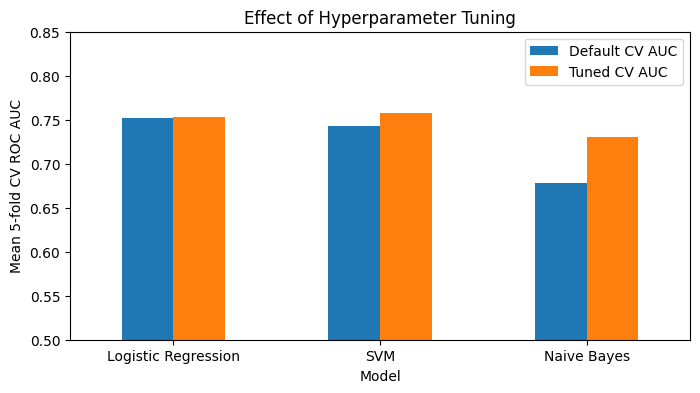

In [57]:

rows = []
for name, scores in searches.items():
    i = scores.best_index_
    rows.append({'Model': name,
                 'Default CV AUC': baseline[name],
                 'Tuned CV AUC': scores.best_score_,
                 'Improvement': scores.best_score_ - baseline[name],
                 'Tuned train AUC': scores.cv_results_['mean_train_score'][i]})
tuning_summary = pd.DataFrame(rows).set_index('Model').round(4)
display(tuning_summary)

tuning_summary[['Default CV AUC', 'Tuned CV AUC']].plot(kind='bar', figsize=(8, 4), ylim=(0.5, 0.85), rot=0)

plt.ylabel('Mean 5-fold CV ROC AUC'); plt.title('Effect of Hyperparameter Tuning');
plt.show()

Observations:

* Tuning led to an improvement in the cross-validated ROC AUC of +0.0012 for the Logistic Regression (0.7516 to 0.7529), +0.0145 for the SVM (0.7427 to 0.7572) and +0.0523 for the Naive Bayes (0.6782 to 0.7305).
* Naive Bayes benefited the most. Its default var_smoothing (10^-9) is very small and many of the one-hot features have very low variances within a class. That leads to extremely unstable likelihoods. A larger value of var_smoothing stabilises the variances and in effect provides some correction for the very unrealistic Gaussian/independence assumptions that Naive Bayes makes on the binary features.
* Logistic Regression didn't really change at all, its defaults (C=1, L2 penalty) were already pretty much in the optimal region.

* Overfitting check (train vs CV AUC):
  * Logistic Regression: 0.781 v 0.753 (gap ~0.028). Little overfitting; the model generalises consistently.
  * Naive Bayes: 0.759 v 0.731 (gap ~0.028). Small gap, the same as Logistic Regression.
  * SVM: 0.856 v 0.757 (gap ~0.099). Clear overfitting, about 3.5 times the gap of the other two models: the flexible RBF kernel fits the training data far better than new data.

  
* Although the tuned SVM has the best CV AUC, its lead over Logistic Regression is only around 0.004. Logistic Regression is of course much simpler, much more stable and vastly more interpretable. That trade-off is looked at in more detail below.

###How individual hyperparameters affect performance
To show the effect of tuning directly, we plot the cross-validated ROC AUC as key hyperparameters change:
- **Logistic Regression:** AUC against `C` for L1 and L2 penalties (the best class_weight for each point);
- **SVM (RBF kernel):** a heatmap of AUC over combinations of `C` and `gamma`.

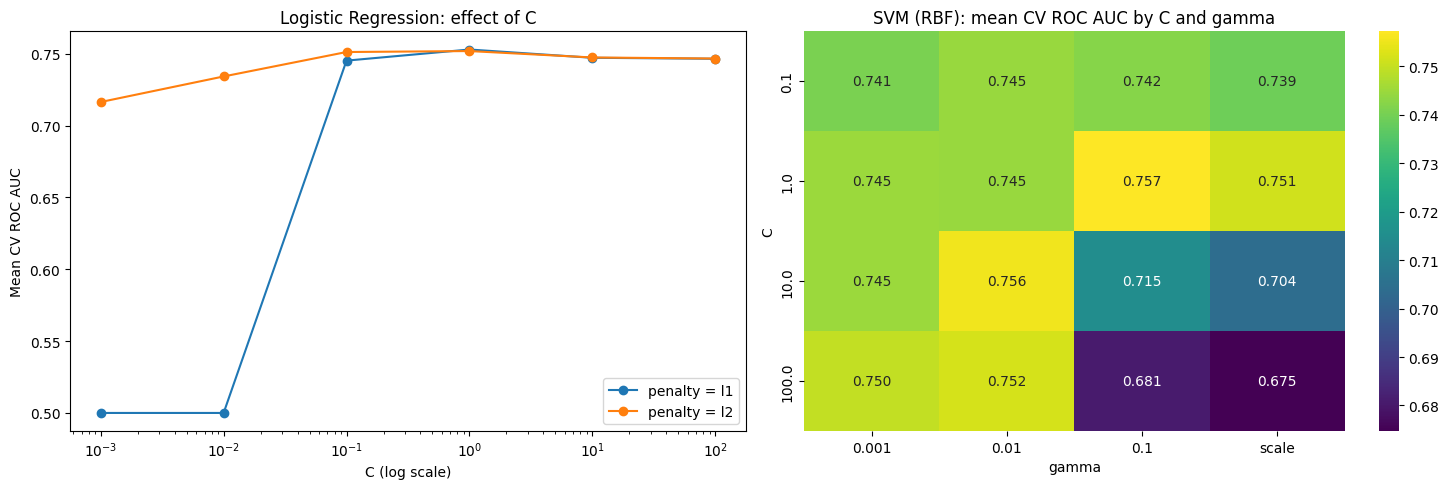

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Logistic Regression: effect of C and penalty
logistic_regression_results = pd.DataFrame(
    searches['Logistic Regression'].cv_results_
)
for penalty, penalty_results in logistic_regression_results.groupby('param_clf__penalty'):
    scores = penalty_results.groupby('param_clf__C')['mean_test_score'].max()

    axes[0].plot(scores.index.astype(float), scores.values, marker='o', label=f'penalty = {penalty}')
axes[0].set_xscale('log'); axes[0].set_xlabel('C (log scale)'); axes[0].set_ylabel('Mean CV ROC AUC')
axes[0].set_title('Logistic Regression: effect of C'); axes[0].legend()

svm_cv_results = pd.DataFrame(searches['SVM'].cv_results_)

svm_rbf_results = svm_cv_results[
    svm_cv_results['param_clf__kernel'] == 'rbf'
].copy()

svm_rbf_results['gamma'] = svm_rbf_results['param_clf__gamma'].astype(str)
svm_rbf_results['C'] = svm_rbf_results['param_clf__C'].astype(float)

svm_performance_matrix = svm_rbf_results.pivot_table(
    index='C',
    columns='gamma',
    values='mean_test_score',
    aggfunc='max'
)

sns.heatmap(
    svm_performance_matrix,
    annot=True,
    fmt='.3f',
    cmap='viridis',
    ax=axes[1]
)

axes[1].set_title('SVM (RBF): mean CV ROC AUC by C and gamma')

plt.tight_layout(); plt.show()


Observations:

* Logistic Regression: with L1 at very small C (0.001 to 0.01) the AUC is precisely 0.50 i.e. no better than random. At that level of regularisation L1 is effectively driving all the coefficients to zero and the model therefore predicts the same probability for every applicant and can't rank them at all (very severe underfitting). Performance improves dramatically at C=0.1 and then peaks at around 0.753 at C=1, after which it plateaus. L2 is much more stable in that at C=0.001 it still achieves an AUC of around 0.72 (all the coefficients are just shrunk a bit). Beyond C~1 there's no benefit to be had from any further flexibility for either penalty.


* SVM (RBF): the best performance (AUC = 0.757) is achieved at C = 1 and gamma = 0.1. AUC drops off dramatically when you go to larger C values in conjunction with larger gamma (0.1 or 'scale') to 0.675 at C = 100 and gamma = 'scale'. That's a classic case of overfitting, the decision boundary is becoming too complex and is fitting the noise in the training data. Small C (0.1) gives slightly lower AUC across the board (a case of mild underfitting). The smaller gamma values (0.001, 0.01) give more consistent performance across the grid (0.741 to 0.756) as they produce smoother boundaries.

These charts demonstrate that hyperparameter selection has a significant impact on performance. The same SVM will give an AUC ranging from 0.675 to 0.757 depending on the settings, so the default values are not necessarily going to be the best.



### Summary
* Three models (Logistic Regression, SVM and Gaussian Naive Bayes) were trained using preprocessing pipelines which were designed to prevent data leakage.
* Each model was tuned via GridSearchCV over the relevant hyperparameters. Stratified 5-fold cross-validation was performed on the training set and ROC AUC was the metric used for selection.
* Tuning improved the CV performance of all the models over their default settings: Logistic Regression by +0.0013, SVM by +0.0145 and Naive Bayes by +0.0523. The hyperparameter plots show the effect of regularisation strength, kernel width and class weighting on performance.
-The three tuned models (each retrained on the full training set) along with the original Logistic Regression, are now evaluated on the held-out test set in next cell implementation.

##6: Model Evaluation and Comparison

The tuned models are now evaluated once on the held-out test set (200 applicants: 140 good, 60 bad), which played no part in training or tuning. This gives an unbiased estimate of how each model would perform on new loan applicants.

###Evaluation metrics
The positive class is **1 = bad (default)**, so each metric describes how well the model identifies risky borrowers:

| Metric | Formula | Meaning in credit risk |
|---|---|---|
| **Accuracy** | (TP + TN) / all | Overall share of correct predictions. Misleading on imbalanced data: predicting "good" for everyone already scores 70% |
| **Precision** | TP / (TP + FP) | Of the applicants flagged as bad, how many really defaulted? Low precision = **good customers wrongly rejected** (lost business) |
| **Recall** | TP / (TP + FN) | Of all actual defaulters, how many did the model catch? Low recall = **defaulters approved** (direct financial loss) |
| **F1-score** | 2 × (Precision × Recall) / (Precision + Recall) | Harmonic mean of precision and recall; a single balanced measure for the minority class |
| **ROC AUC** | Area under the ROC curve | Probability that a randomly chosen defaulter is ranked as riskier than a randomly chosen good borrower; independent of the decision threshold |

For a lender, a false negative (approving someone who defaults) usually costs far more than a false positive (rejecting a good customer), because it can mean losing the whole loan amount rather than one customer's interest. Recall and ROC AUC are therefore given particular weight, alongside F1.

We also include a baseline that always predicts "good" (the majority class), to show why accuracy alone is not a meaningful measure here.

In [59]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, ConfusionMatrixDisplay, classification_report
)

from sklearn.dummy import DummyClassifier


model_probabilities = {
    'LR (from scratch)': scratch.predict_proba(X_test_p),
    'Logistic Regression (tuned)': searches['Logistic Regression'].predict_proba(X_test)[:, 1],
    'SVM (tuned)': searches['SVM'].predict_proba(X_test)[:, 1],
    'Naive Bayes (tuned)': searches['Naive Bayes'].predict_proba(X_test)[:, 1],
}


dummy = DummyClassifier(strategy='most_frequent').fit(X_train_p, y_train)

model_probabilities['Baseline (always "good")'] = dummy.predict_proba(X_test_p)[:, 1]



def evaluate(y_true, probabilities, threshold=0.5):
    predictions = (probabilities >= threshold).astype(int)

    return {
        'Accuracy': accuracy_score(y_true, predictions),
        'Precision': precision_score(y_true, predictions, zero_division=0),
        'Recall': recall_score(y_true, predictions),
        'F1-score': f1_score(y_true, predictions),
        'ROC AUC': roc_auc_score(y_true, probabilities)
    }



results = pd.DataFrame({
    model_name: evaluate(y_test, predicted_probabilities)
    for model_name, predicted_probabilities in model_probabilities.items()
}).T.round(4)

display(
    results.style
    .highlight_max(axis=0, color='lightgreen')
    .format('{:.4f}')
)

,Accuracy,Precision,Recall,F1-score,ROC AUC
LR (from scratch),0.7300,0.5789,0.3667,0.4490,0.7552
Logistic Regression (tuned),0.7250,0.5676,0.3500,0.4330,0.7573
SVM (tuned),0.7600,0.6500,0.4333,0.5200,0.7910
Naive Bayes (tuned),0.7250,0.5510,0.4500,0.4954,0.7436
"Baseline (always ""good"")",0.7000,0.0000,0.0000,0.0000,0.5000


Observations:

* The tuned SVM does best at the default 0.5 threshold on 4/5 of the metrics: accuracy 0.760, precision 0.650, F1 0.520 and ROC AUC 0.791. Its ROC AUC is the best of the bunch (the others range from 0.744 to 0.757).
* Naive Bayes has the best recall (0.450) so catches the most defaulters, but it has the worst precision (0.551) and so also flags up far more good customers as well.
* Both the logistic regression models have very low recall (0.350 to 0.367) at the 0.5 threshold. As predicted from Step 5, the tuned model is using class_weight=None and so is being quite cautious about labelling the minority "bad" class.
* The baseline that just predicts “good” gets 70% accuracy but 0% recall, 0% F1 and an AUC of 0.5. It approves every single defaulter. All four of the models outperform it by only 2.0–6.0 percentage points in terms of accuracy. That really highlights the fact that accuracy is a very misleading metric on this imbalanced dataset and why recall, F1 and ROC AUC are so important.
* The from scratch Logistic Regression performs pretty much the same as the tuned scikit-learn Logistic Regression (AUC 0.755 v 0.757, F1 0.449 v 0.433). That confirms the Step 4 is correct. The slight differences are due to the different regularisation (L2 with C=1 v L1 with C=1).
* Note that the test set only has 60 defaulters so small differences between the models (a few hundredths of an AUC) could easily be down to chance. The SVM's test AUC is 0.791 which is higher than its cross-validated AUC of 0.757. The LR on the other hand has a test AUC of 0.757 which is virtually identical to its cross-validated AUC of 0.753. So LR's performance is a much more stable estimate.

### Confusion matrices
A confusion matrix breaks the predictions into four groups, showing exactly what kind of mistakes each model makes:
- **True Negatives (top-left):** good borrowers correctly approved
- **False Positives (top-right):** good borrowers wrongly rejected (lost business)
- **False Negatives (bottom-left):** defaulters wrongly approved (**financial loss**, the costliest error)
- **True Positives (bottom-right):** defaulters correctly identified

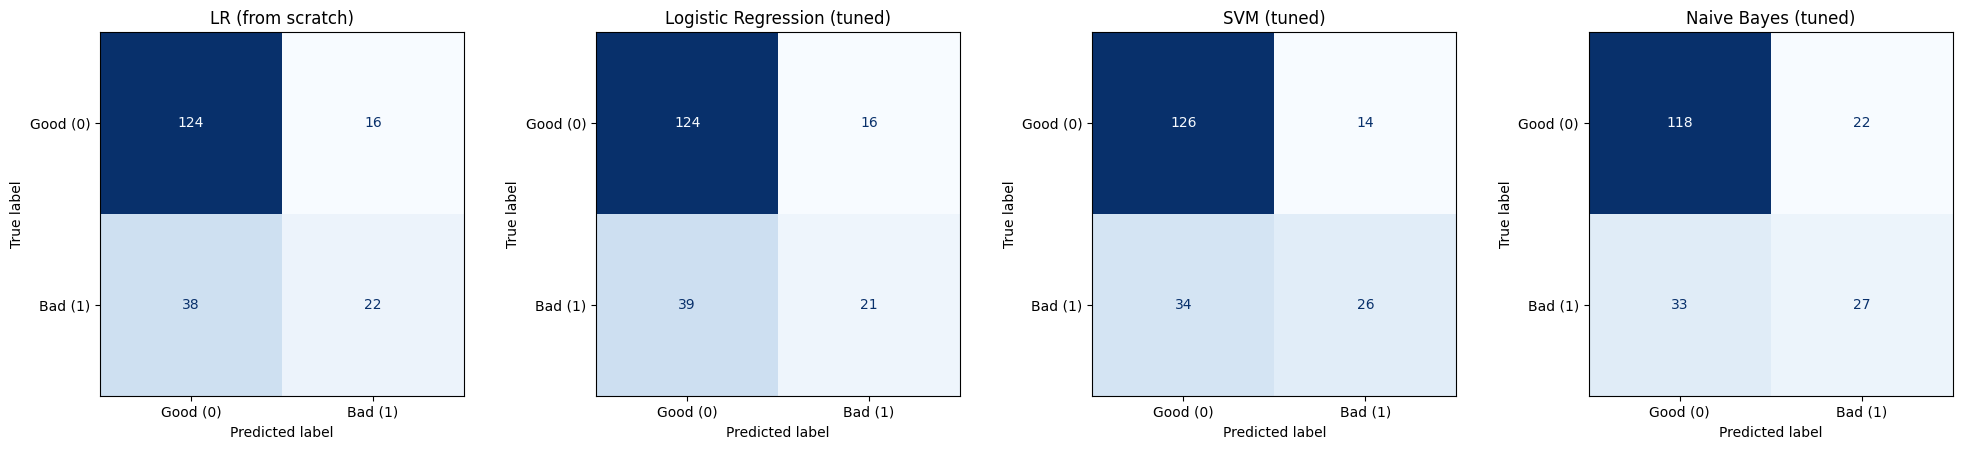

In [60]:
model_names_to_plot = [
    model_name for model_name in model_probabilities
    if not model_name.startswith('Baseline')
]

fig, axes = plt.subplots(
    1, len(model_names_to_plot), figsize=(20, 4.5)
)

for plot_index, model_name in enumerate(model_names_to_plot):

    predicted_classes = (
        model_probabilities[model_name] >= 0.5
    ).astype(int)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predicted_classes,
        display_labels=['Good (0)', 'Bad (1)'],
        cmap='Blues',
        colorbar=False,
        ax=axes[plot_index]
    )

    axes[plot_index].set_title(model_name)

plt.tight_layout()
plt.show()

**Observations:**

test set: 140 good, 60 bad applicants

| Model | Defaulters caught (TP) | **Defaulters missed (FN)** | Good customers rejected (FP) | Good customers approved (TN) |
|---|---|---|---|---|
| LR (from scratch) | 22 | 38 | 16 | 124 |
| Logistic Regression (tuned) | 21 | 39 | 16 | 124 |
| SVM (tuned) | 26 | 34 | **14** | **126** |
| Naive Bayes (tuned) | **27** | **33** | 22 | 118 |

* All the models miss over half the defaulters at the 0.5 threshold, approving between 33 and 39 of the 60. That's the most expensive error in real lending.
* SVM is the best. Catches 26 defaults and only rejects 14 of the good ones.
* Naive Bayes picks up the most defaulters (27) but also rejects the most good customers (22). That's the classic trade-off between precision and recall: you can catch more of the bad customers but at the cost of rejecting a lot of the good ones.
* The two Logistic Regression models are virtually identical, differing by just one applicant.

### ROC curves and visual comparison
The ROC curve plots the true positive rate (recall) against the false positive rate at every possible decision threshold. A curve closer to the top-left corner means better discrimination; the diagonal line represents random guessing (AUC = 0.5). A bar chart summarises all five metrics side by side.

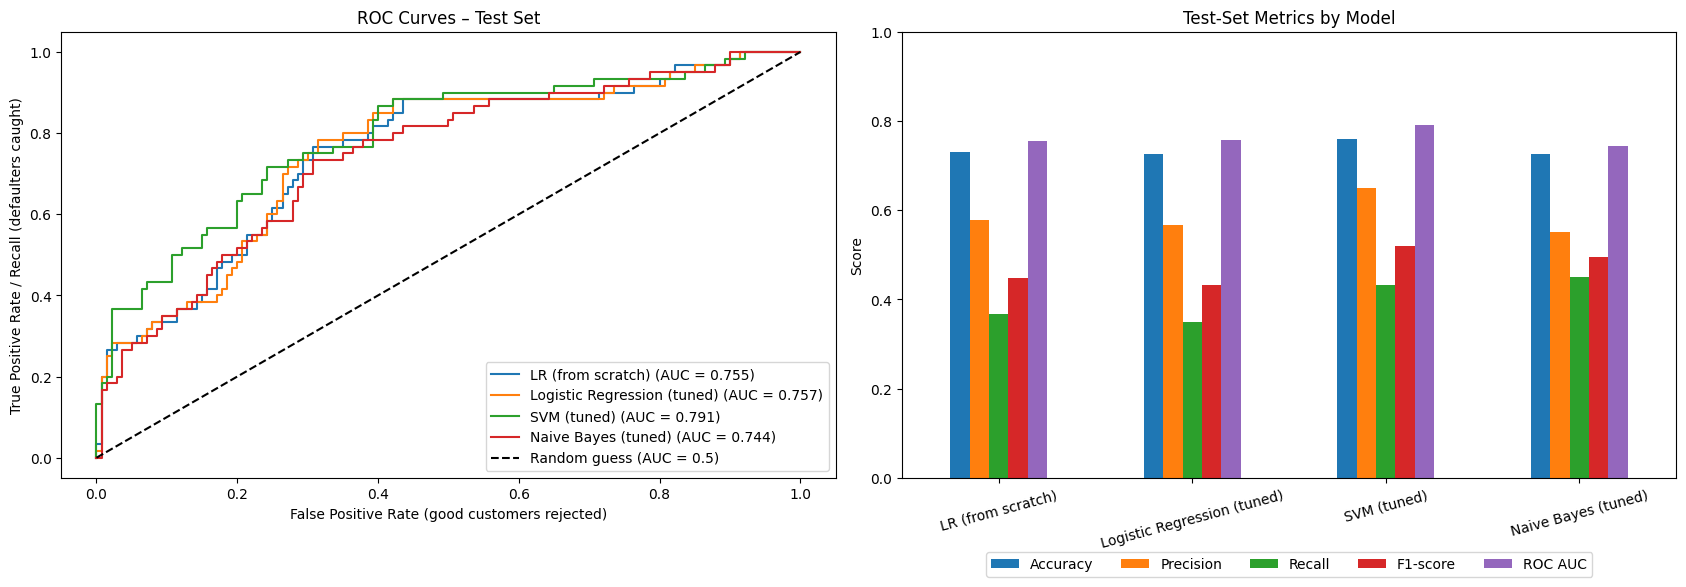

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

# Plot ROC curves for each model
for model_name in model_names_to_plot:
    false_positive_rate, true_positive_rate, _ = roc_curve(
        y_test, model_probabilities[model_name]
    )

    axes[0].plot(
        false_positive_rate,
        true_positive_rate,
        label=f'{model_name} (AUC = {roc_auc_score(y_test, model_probabilities[model_name]):.3f})'
    )

axes[0].plot(
    [0, 1], [0, 1],
    'k--',
    label='Random guess (AUC = 0.5)'
)

axes[0].set_xlabel('False Positive Rate (good customers rejected)')
axes[0].set_ylabel('True Positive Rate / Recall (defaulters caught)')
axes[0].set_title('ROC Curves – Test Set')
axes[0].legend(loc='lower right')


# Plot test-set performance metrics
results.loc[model_names_to_plot].plot(
    kind='bar',
    ax=axes[1],
    rot=15,
    ylim=(0, 1)
)

axes[1].set_title('Test-Set Metrics by Model')
axes[1].set_ylabel('Score')
axes[1].legend(
    loc='upper center',
    bbox_to_anchor=(0.5, -0.15),
    ncol=5
)

plt.tight_layout()
plt.show()

### Observation:


All four ROC curves are well above the random-guess diagonal, showing that each model can distinguish defaulters from good borrowers. The SVM curve is the highest, especially at low false positive rates on the left side of the chart. This means that when the lender wants to reject only a few good customers, the SVM identifies the most defaulters. As the false positive rate increases, the curves come together and mostly overlap, so the models perform similarly when more rejections are allowed. Naive Bayes usually has the lowest curve.


### Addressing class imbalance: adjusting the decision threshold
By default, an applicant is classified as bad when P(bad) ≥ 0.5. Because only 30% of applicants are bad, and because the tuned Logistic Regression uses `class_weight=None`, this threshold can make the model too cautious about flagging defaulters (low recall).

Since a missed defaulter is the costliest error, a lender can lower the threshold to catch more of them, at the cost of rejecting some more good customers. To avoid data leakage, the threshold is not chosen using the test set. Instead we:
1. generate out-of-fold predicted probabilities on the training set with 5-fold cross-validation;
2. choose the threshold that maximises F1 on those predictions;
3. apply that threshold, unchanged, to the test set.


Threshold chosen on training data (max F1): 0.300


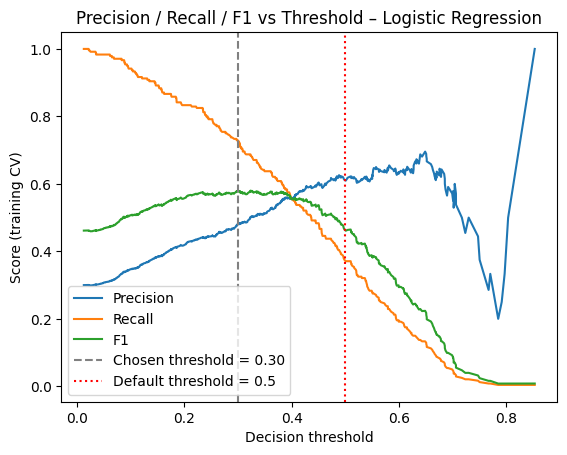

,Accuracy,Precision,Recall,F1-score,ROC AUC
LR (from scratch),0.7300,0.5789,0.3667,0.4490,0.7552
Logistic Regression (tuned),0.7250,0.5676,0.3500,0.4330,0.7573
SVM (tuned),0.7600,0.6500,0.4333,0.5200,0.7910
Naive Bayes (tuned),0.7250,0.5510,0.4500,0.4954,0.7436
"Baseline (always ""good"")",0.7000,0.0000,0.0000,0.0000,0.5000
Logistic Regression (threshold = 0.30),0.7200,0.5244,0.7167,0.6056,0.7573


In [62]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

# Retrieve the best Logistic Regression model
best_logistic_regression = searches['Logistic Regression'].best_estimator_

# Generate out-of-fold predicted probabilities on the training set
out_of_fold_probabilities = cross_val_predict(
    best_logistic_regression,
    X_train,
    y_train,
    cv=cross_validation,
    method='predict_proba'
)[:, 1]


precision_values, recall_values, decision_thresholds = precision_recall_curve(
    y_train,
    out_of_fold_probabilities
)

# Calculate F1 scores across all decision thresholds
f1_scores = (
    2 * precision_values[:-1] * recall_values[:-1]
    / (precision_values[:-1] + recall_values[:-1] + 1e-12)
)


best_threshold = decision_thresholds[np.argmax(f1_scores)]

print(
    f'Threshold chosen on training data (max F1): {best_threshold:.3f}'
)


plt.plot(decision_thresholds, precision_values[:-1], label='Precision')
plt.plot(decision_thresholds, recall_values[:-1], label='Recall')
plt.plot(decision_thresholds, f1_scores, label='F1')

plt.axvline(
    best_threshold,
    ls='--',
    c='grey',
    label=f'Chosen threshold = {best_threshold:.2f}'
)

plt.axvline(
    0.5,
    ls=':',
    c='red',
    label='Default threshold = 0.5'
)

plt.xlabel('Decision threshold')
plt.ylabel('Score (training CV)')
plt.legend()
plt.title('Precision / Recall / F1 vs Threshold – Logistic Regression')
plt.show()


results.loc[
    f'Logistic Regression (threshold = {best_threshold:.2f})'
] = evaluate(
    y_test,
    model_probabilities['Logistic Regression (tuned)'],
    threshold=best_threshold
)


display(
    results.round(4)
    .style
    .highlight_max(axis=0, color='lightgreen')
    .format('{:.4f}')
)

**Observations:**
* Using 5-fold cross-validated predictions on the training set only, the threshold that maximises F1 is 0.30. That's why the precision/recall chart makes sense: at the default of 0.5 recall is already down to around 0.4, whereas at 0.30 recall is very high (around 0.7) and F1 is at its peak.
* Applied unchanged to the test set, lowering the threshold from 0.5 to 0.30 had the effect of improving the Logistic Regression's performance on the bad class:

| Metric | Threshold 0.5 | Threshold 0.30 | Change |
|---|---|---|---|
| Recall | 0.350 | **0.717** | +0.367 |
| F1-score | 0.433 | **0.606** | +0.173 |
| Precision | 0.568 | 0.524 | −0.044 |
| Accuracy | 0.725 | 0.720 | −0.005 |
| ROC AUC | 0.757 | 0.757 | unchanged |

* In practical terms it's now picking up 43 of the 60 defaulters rather than 21 (22 more), at the cost of rejecting 23 more good customers (39 instead of 16). Accuracy is pretty much unchanged which again shows you that accuracy is a very poor measure of what's really going on here.
* Logistic Regression hits the highest recall and the highest F1-score of any of the models at this threshold.
* ROC AUC is unchanged as it's a measure of ranking across all thresholds. The threshold merely determines where the line is drawn between 'approve' and 'reject'. It's therefore a business lever - the lender can set the threshold where they see fit depending on the relative cost of a missed defaulter versus a good customer who gets rejected.

###Strengths and weaknesses of each model for credit risk

| Model | Strengths | Weaknesses |
|---|---|---|
| **Logistic Regression** (scratch & tuned) | Highly interpretable. Each coefficient shows how a feature changes the odds of default, which is essential for explaining decisions to applicants and regulators. Produces well-calibrated probabilities that can be used directly for risk-based pricing. Fast and stable, with little overfitting (train/CV AUC gap ≈ 0.028). L1 penalty performs automatic feature selection | Assumes a linear relationship between features and the log-odds of default, so it can miss interactions. With unweighted classes, the default 0.5 threshold gives low recall, so the threshold needs adjusting |
| **SVM (RBF, balanced)** | Can model non-linear relationships; balanced class weights improve detection of defaulters;  highest ROC AUC in both cross-validation (0.757) and on the test set (0.791) | A black box: with an RBF kernel there are no coefficients to explain individual decisions, which is a problem in regulated lending. Showed the most overfitting (train AUC 0.856 vs CV 0.757, a gap of ≈ 0.099). Slower to train, very sensitive to C and gamma, and its probabilities come from an extra calibration step |
| **Gaussian Naive Bayes** | Extremely fast; needs little data; simple | Assumes features are independent and normally distributed, both violated here (e.g. Credit amount and Duration are correlated, r ≈ 0.62; one-hot features are binary, not Gaussian). Lowest CV AUC and benefited most from tuning, which shows how sensitive it is to these assumptions |

### Choosing the best model

Best raw predictive performance is SVM (RBF kernel). At the default threshold it had the best accuracy (0.760), precision (0.650), F1 (0.520) and ROC AUC (0.791) on the test set.

Recommended model for credit risk decisions: Logistic Regression (L1, C = 1) with a decision threshold of 0.30. The reasons:

1. It achieves the business objective best. With the adjusted threshold it has the highest recall (0.717) and the highest F1 score (0.606) of any of the models. The defaults it misses are by far the most expensive type of error in lending.
2. The SVM's ranking advantage is tiny and very uncertain. In CV the gap between SVM and Logistic Regression was only 0.004 AUC (0.757 vs 0.753). The larger gap on the test set is due to just 60 defaulters and the SVM clearly overfitted (train AUC 0.870 vs CV 0.757). Logistic Regression's performance on the test set was very much in line with its CV performance so it is the more stable and predictable of the two.
3. Interpretability. In lending you often have to explain your decisions to applicants and to regulators. The LR coefficients tell you precisely how each factor increases or decreases the odds of default. The RBF SVM is a black box.
4. Simplicity and consistency. It's fast,shows little overfitting (train/CV gap of only 0.028, versus 0.099 for the SVM) and provides reliable probabilities which can also be used for risk based pricing.

Limitation: the SVM threshold was not tuned and tuning it would probably have an effect on its recall as well. That said it wouldn't have got rid of the overfitting or the lack of interpretability.

Logistic Regression is used for the feature importance analysis in next step.

## 7. Feature Importance and Interpretation

Step 6 selected **Logistic Regression (L1, C = 1)** as the recommended model. A key advantage of logistic regression is that its **coefficients directly show how each feature influences the predicted risk of default**, so the model's decisions can be explained to managers, applicants and regulators.


### How to interpret the coefficients
The model predicts the **log-odds of default**: log(P(bad) / P(good)) = b + w₁x₁ + w₂x₂ + …

- **Sign:** a **positive** coefficient **increases** the risk of default; a **negative** coefficient **decreases** it.
- **Magnitude:** because all numerical features were standardised and all categorical features are 0/1, the absolute size of the coefficients can be compared to **rank** feature influence.
- **Odds ratio = e^coefficient:** the factor by which the odds of default are multiplied. An odds ratio of 1.5 means 50% higher odds of default; 0.6 means 40% lower odds.
- **Numerical features** (`Age`, `Credit amount`, `Duration`, `Job`): the effect of an increase of **one standard deviation**.
- **One-hot features:** the effect **relative to the reference category** that was dropped in Step 3 (`drop='first'`):

| Feature | Reference category (coefficient = 0) |
|---|---|
| Sex | female |
| Housing | free |
| Saving accounts | little |
| Checking account | little |
| Purpose | business |

  For example, a negative coefficient for `Checking account_rich` means applicants with a rich checking account have *lower* default risk than those with a "little" balance.
- **L1 penalty:** coefficients of exactly **0** were removed by L1 regularisation, because the model judged those features not useful enough to keep. This is built-in feature selection.

In [63]:
best_logistic_regression = searches['Logistic Regression'].best_estimator_

feature_names = best_logistic_regression.named_steps['pre'].get_feature_names_out()
feature_coefficients = best_logistic_regression.named_steps['clf'].coef_[0]

coefficient_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': feature_coefficients,
    'Odds ratio': np.exp(feature_coefficients)
})

coefficient_df['Feature'] = (
    coefficient_df['Feature']
    .str.replace('numerical__', '')
    .str.replace('categorical__', '')
)

coefficient_df['Effect on default risk'] = np.select(
    [
        coefficient_df['Coefficient'] > 0,
        coefficient_df['Coefficient'] < 0
    ],
    [
        'Increases risk',
        'Decreases risk'
    ],
    default='Removed by L1 (no effect)'
)

coefficient_df = (
    coefficient_df
    .reindex(
        coefficient_df['Coefficient']
        .abs()
        .sort_values(ascending=False)
        .index
    )
    .reset_index(drop=True)
)

coefficient_df.index += 1
coefficient_df.index.name = 'Rank'

display(coefficient_df.round(4))

print(
    'Intercept:',
    round(best_logistic_regression.named_steps['clf'].intercept_[0], 4)
)

print(
    'Features kept by L1:',
    (coefficient_df['Coefficient'] != 0).sum(),
    'of',
    len(coefficient_df)
)

print(
    'Features removed by L1:',
    list(
        coefficient_df.loc[
            coefficient_df['Coefficient'] == 0,
            'Feature'
        ]
    )
)

,Feature,Coefficient,Odds ratio,Effect on default risk
Rank,,,,
1,Checking account_unknown,-1.5859,0.2048,Decreases risk
2,Saving accounts_rich,-0.9512,0.3863,Decreases risk
3,Saving accounts_unknown,-0.8455,0.4294,Decreases risk
4,Purpose_education,0.7467,2.1101,Increases risk
5,Checking account_rich,-0.5449,0.5799,Decreases risk
6,Duration,0.5198,1.6817,Increases risk
7,Saving accounts_quite rich,-0.3688,0.6916,Decreases risk
8,Sex_male,-0.3640,0.6949,Decreases risk
9,Housing_rent,0.3357,1.3989,Increases risk


Intercept: 0.1716
Features kept by L1: 16 of 21
Features removed by L1: ['Job', 'Saving accounts_moderate', 'Purpose_domestic appliances', 'Purpose_furniture/equipment', 'Purpose_vacation/others']


###Visualising feature influence
The chart shows every feature kept by the model, ordered by coefficient. Red bars increase the risk of default and green bars decrease it; the longer the bar, the stronger the influence.


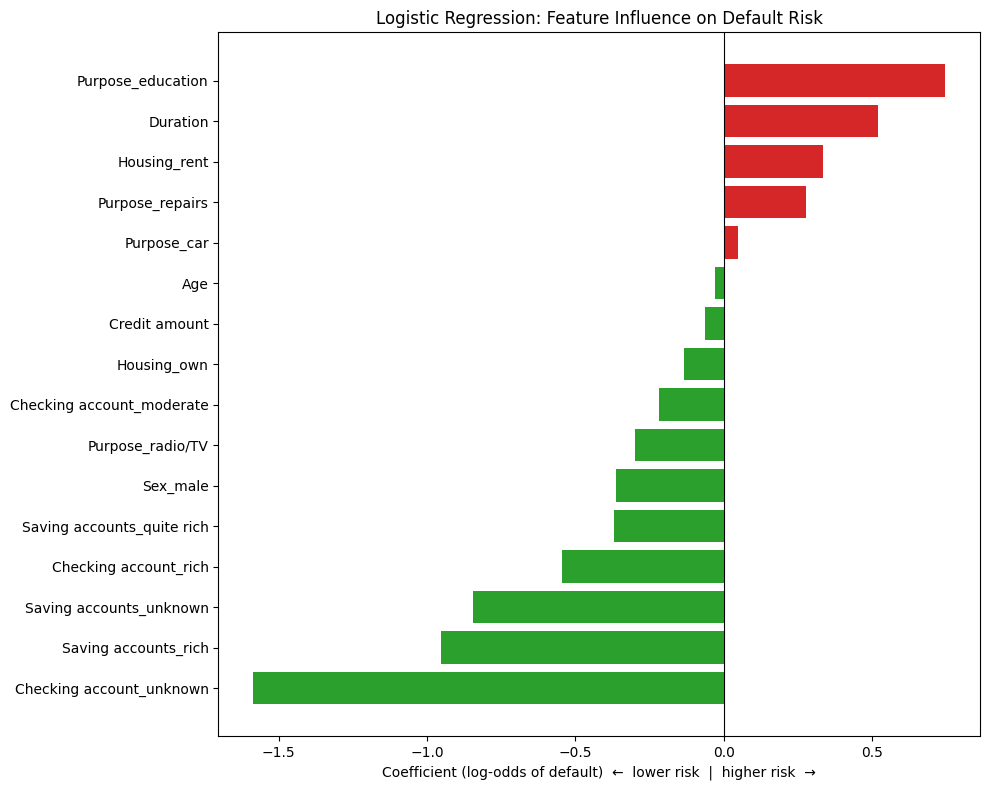

In [64]:
nonzero_coefficients = (
    coefficient_df[coefficient_df['Coefficient'] != 0]
    .sort_values('Coefficient')
)

bar_colors = [
    '#d62728' if coefficient > 0 else '#2ca02c'
    for coefficient in nonzero_coefficients['Coefficient']
]

plt.figure(figsize=(10, 8))

plt.barh(
    nonzero_coefficients['Feature'],
    nonzero_coefficients['Coefficient'],
    color=bar_colors
)

plt.axvline(0, color='black', lw=0.8)

plt.xlabel('Coefficient (log-odds of default)  ←  lower risk  |  higher risk  →')
plt.title('Logistic Regression: Feature Influence on Default Risk')

plt.tight_layout()
plt.show()

OBSERVATION:

ranked feature influence (L1 Logistic Regression):

| Rank | Feature | Odds ratio | Effect on odds of default |
|---|---|---|---|
| 1 | Checking account = unknown (vs little) | 0.205 | **−79.5%** |
| 2 | Saving accounts = rich (vs little) | 0.386 | −61.4% |
| 3 | Saving accounts = unknown (vs little) | 0.429 | −57.1% |
| 4 | Purpose = education (vs business) | 2.112 | **+111.2%** |
| 5 | Checking account = rich (vs little) | 0.580 | −42.0% |
| 6 | Duration (per +1 std dev ≈ 10.5 months) | 1.682 | **+68.2%** |
| 7 | Saving accounts = quite rich (vs little) | 0.692 | −30.8% |
| 8 | Sex = male (vs female) | 0.695 | −30.5% |
| 9 | Housing = rent (vs free) | 1.403 | +40.3% |
| 10 | Purpose = radio/TV (vs business) | 0.742 | −25.8% |

**Key findings:**
- **Checking account status is the single most influential factor.** Compared with a "little" balance, the odds of default fall steadily as the balance rises: moderate −19.7%, rich −42.0%, and unknown (most likely *no checking account*) −79.5%. This confirms the EDA finding that the missing values were highly informative, and justifies keeping them as a separate category in step (2).

* **Savings show a clear protective gradient**. moderate savings have no effect relative to "little" (L1 removed this feature), quite rich lowers the odds by 30.8% and rich by 61.4%. Higher levels of savings provide a financial buffer against missed repayments.
* Loan duration is the single most significant numerical risk factor. The longer the loan, the greater the time available for the applicant's circumstances to change.
* Loan purpose is important: education loans have over twice the chance of default as business loans and repairs loans are also more risky (+32.0%) whereas radio/TV loans are actually less risky (−25.8%).
* Credit amount and Age have very small coefficients (ranks 14 and 16). In the EDA the defaulters did in fact take larger loans on average, but credit amount is correlated with duration (r ≈ 0.62). Once duration is in the model the amount contributes almost nothing so it's the length of the loan rather than the size of the loan which is the driver of risk.
* L1 regularisation got rid of 5 of the 21 features: Job, Saving accounts_moderate and the purposes domestic appliances, furniture/equipment and vacation/others. These all carry no useful additional information (again this is consistent with the EDA which showed that default rates were pretty much the same across all levels of job skill). The final model is therefore simpler and uses 16 features.
* Note that each coefficient is a conditional effect (all other features held constant). So for instance renting is associated with higher risk than free housing in the model even though free housing actually had the highest raw default rate in the EDA. That's because free housing is associated with other characteristics which the model has already taken into account.


### Translating numerical effects into real-world units
Coefficients for numerical features are expressed per standard deviation, which is hard to relate to a real loan. Using the standard deviations learned by the scaler, we convert them into intuitive units: **odds ratio for a change of k units = e^(coefficient × k / standard deviation)**.

In [65]:
numerical_scaler = best_logistic_regression.named_steps['pre'].named_transformers_['numerical']

feature_unit_changes = {
    'Age': (10, '+10 years'),
    'Credit amount': (1000, '+1,000 DM'),
    'Duration': (12, '+12 months'),
    'Job': (1, '+1 skill level')
}

odds_ratio_results = []

for feature_index, feature_name in enumerate(numerical_features):
    unit_multiplier, change_label = feature_unit_changes[feature_name]

    odds_ratio = np.exp(
        feature_coefficients[feature_index]
        * unit_multiplier
        / numerical_scaler.scale_[feature_index]
    )

    odds_ratio_results.append({
        'Feature': feature_name,
        'Change': change_label,
        'Std dev (training)': numerical_scaler.scale_[feature_index],
        'Odds ratio': odds_ratio,
        'Change in odds of default': f'{(odds_ratio - 1) * 100:+.1f}%'
    })

numerical_feature_effects_df = pd.DataFrame(odds_ratio_results)

display(numerical_feature_effects_df.round(3))

,Feature,Change,Std dev (training),Odds ratio,Change in odds of default
0,Age,+10 years,10.623,0.974,-2.6%
1,Credit amount,"+1,000 DM",2158.317,0.971,-2.9%
2,Duration,+12 months,10.538,1.807,+80.7%
3,Job,+1 skill level,0.642,1.000,+0.0%


Observation:

* Duration: each additional 12 months of loan term increases the odds of default by 80.8% (OR 1.81). A 36 month loan therefore has about 1.8 times the odds of default of an otherwise identical 24 month loan. This is by far the biggest number.
* Credit amount: each additional 1,000 DM only changes the odds by −2.9% (a very small effect once duration is taken into account). The slightly negative sign should not be read as "the larger the loan the safer it is" (that would be a very odd interpretation) it's simply a result of the overlap with duration.
* Age: for each additional 10 years you go the reduction in the odds of default is only 2.6% which is a very small effect.
* Job: 0% (the feature was removed by L1 regularisation).

In practical terms how long the loan lasts is by far the more pertinent warning sign than how much is borrowed or who it is that is borrowing it (in terms of age and job).

###Robustness check: permutation importance
Coefficients show the effect of each *encoded column*. As a model-independent cross-check, we use **permutation importance**: each original feature is randomly shuffled in the test set, and we measure how much the model's ROC AUC drops. A large drop means the model relies heavily on that feature. Because it works on the original 9 features, it also gives the overall importance of each categorical variable (combining all its one-hot columns).

Applying the same method to the **SVM** provides some **explainability for the black-box model**, and shows whether both models rely on the same factors.

,LR: drop in AUC,SVM: drop in AUC
Checking account,0.1504,0.1496
Duration,0.0651,0.0813
Saving accounts,0.0098,0.0131
Age,0.0013,0.0237
Job,0.0000,0.0269
Sex,-0.0001,0.0106
Credit amount,-0.0019,0.0235
Housing,-0.0037,0.0044
Purpose,-0.0050,0.0031


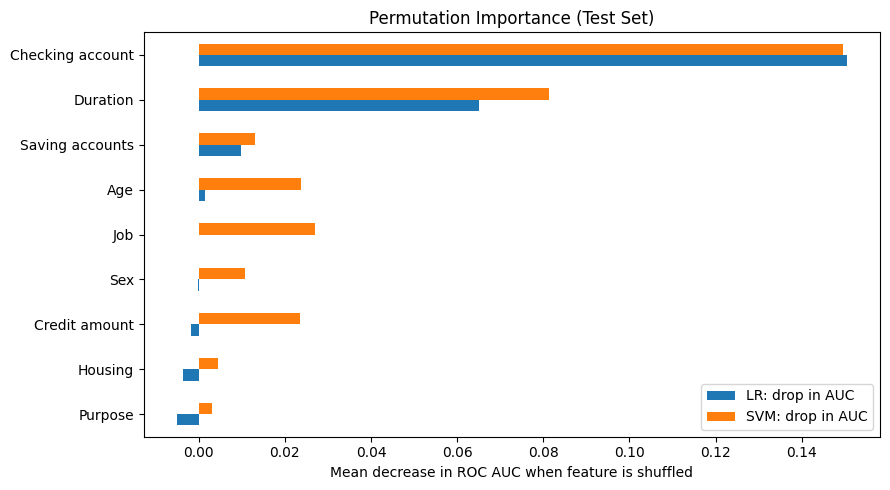

In [66]:
from sklearn.inspection import permutation_importance

permutation_importance_results = {}

for model_name in ['Logistic Regression', 'SVM']:
    importance_result = permutation_importance(
        searches[model_name].best_estimator_,
        X_test,
        y_test,
        scoring='roc_auc',
        n_repeats=30,
        random_state=42,
        n_jobs=-1
    )

    permutation_importance_results[model_name] = pd.Series(
        importance_result.importances_mean,
        index=X_test.columns
    )

permutation_importance_df = (
    pd.DataFrame(permutation_importance_results)
    .sort_values('Logistic Regression', ascending=False)
)

permutation_importance_df.columns = [
    'LR: drop in AUC',
    'SVM: drop in AUC'
]

display(permutation_importance_df.round(4))

permutation_importance_df.sort_values('LR: drop in AUC').plot(
    kind='barh',
    figsize=(9, 5)
)

plt.xlabel('Mean decrease in ROC AUC when feature is shuffled')
plt.title('Permutation Importance (Test Set)')
plt.tight_layout()
plt.show()


**Observations:**

* Both models agree on the two main features: shuffling the Checking account leads to a reduction in ROC AUC of approximately 0.15 for both the Logistic Regression and SVM models, and shuffling Duration leads to a reduction of approximately 0.065 (LR) and 0.08 (SVM). All the other features have a far smaller effect. This independently validates the coefficient analysis.
* Saving accounts is the third most important feature for Logistic Regression (c. 0.01).
* Purpose had the largest single coefficient (education) but almost no permutation importance. Education loans are pretty rare (around 6% of applicants) so whilst the effect on an individual applicant is huge, permuting that feature makes very little difference to the number of predictions. This is a good example of the fact that a large coefficient doesn't necessarily imply that a feature is important to the model. How frequently a category occurs is also a factor.
* For logistic regression: Sex, Job, Age, Credit amount, Housing and Purpose all have near zero or very slightly negative importance on the test set. A negative value means that shuffling that feature made no difference (or indeed made a very slight improvement in AUC by chance) so the model's test performance is not at all dependent on those features.
* The SVM spreads its reliance much more broadly, picking up small amounts (approx 0.01-0.03) from Job, Age, Credit amount and Sex. The non-linear kernel is able to capture interactions between these features which is why it has the slightly higher test AUC. This also accounts for the greater overfitting observed in Step 5 and why its decisions are so much harder to interpret.
* This analysis also gives the black box SVM a degree of explainability in that it's essentially relying on the same two factors as the Logistic Regression.

### Using these insights for credit decision-making

The analysis turns the model into practical guidance for a lender:

1. Credit approval policy

  - Checking account status should be at the heart of any assessment. It's the most significant factor in both models. The "little" checking balance group are by far the highest risk (49% default rate in the data) so the bank could in principle require further verification from that group (e.g. proof of income, recent statements etc).
  * Savings act as a buffer. Those with "rich" savings have 61% lower odds of default than those with little savings and so could be eligible for fast track, whereas those with little savings may be asked for a collateral or a guarantor.

2. Loan structuring

* Loan duration not loan amount is the primary structural risk driver. An extra 12 months of loan duration increases the odds of default by around 81%, an extra 1,000 DM has virtually no impact. For the higher risk applicant the answer is therefore to offer a shorter term (if necessary with higher instalments) rather than just reduce the loan amount. That keeps the customer and significantly reduces risk.
* Purpose based limits: education loans (more than twice the odds of default of a business loan) and repair loans would merit the strictest of checks or limits, whereas lower risk purposes such as radio/TV purchases could be approved with ease.

3. Risk-based pricing

* The model will produce a probability of default for every applicant. That can be used to set the interest rate. The low risk profiles (e.g. healthy checking and savings balances, short duration) will get the best rates which makes the bank more competitive. The higher risk profiles will pay a premium which covers the expected loss.

4. Setting the decision threshold

* As in Step 6, reducing the threshold from 0.5 to 0.30 more than doubled the number of defaulters picked up (from 21 to 43 of 60) at the expense of rejecting 23 more good customers. The threshold should be set based on the actual cost of a default versus the profit lost by rejecting a good customer and it should be reviewed as the economic climate changes.

5. Fairness and regulation

* Sex has a significant coefficient (male applicants have 30.5% lower odds of default than female applicants, all else being equal) but its permutation importance is essentially zero. The use of sex in credit decisions is banned or restricted in many jurisdictions (EU anti-discrimination rules and the US Equal Credit Opportunity Act to name just two) and is plainly ethically dubious. As it contributes nothing to the model's predictive performance it should be removed from a production model at negligible cost and the model should be audited for bias across groups (including via proxy variables).
* Age is also a protected characteristic in certain circumstances. The effect here is very minor (−2.6% per 10 years) so it could be removed following review by compliance.
* Logistic Regression is interpretable so you can give the applicant a clear reason for the rejection (e.g. "low checking account balance and long loan duration") which is a legal requirement in many jurisdictions (e.g. GDPR's requirements around automated decision making).

6. Limitations

* The data is 1,000 historical applicants from Germany so it's unlikely to transfer directly to other markets or time periods. It would need to be retrained and monitored over time.
* Coefficients show association not causation. Having substantial savings is associated with lower risk, for instance, but the model can't show that having savings causes you to repay.

### Conclusion

In this lab we've built a full machine learning pipeline for credit risk prediction on the German Credit dataset. The details of what we've done so far and the output summary are as follows:

* EDA revealed an imbalanced target (70% good, 30% bad), some informative missingness in the account columns and a number of skewed numerical features with outliers.
* Preprocessing left the missing values as 'unknown', capped the outliers using the IQR method, one hot encoded the nominal features and standardised the numerical features all in a leakage free order.
* Logistic Regression was implemented from scratch using gradient descent, converged very nicely and gave essentially the same results as scikit-learn.
* Three models were tuned using GridSearchCV with stratified 5-fold cross validation. All of the models saw some improvement as a result of the tuning, with Naive Bayes being the biggest winner (+0.052 AUC).
* On the test set the SVM achieved the highest ROC AUC (0.791), but the Logistic Regression with the adjusted threshold (0.30) had the best recall (0.717) and F1 (0.606). It was also the most stable and was fully interpretable so that's the model we'd recommend.
- Our feature analysis has established that checking account status, loan term and savings are the key drivers of default risk (as evidenced by both the model coefficients and the permutation importance). Loan term is by far the most important factor of all, far more so than loan size. This is obviously going to have a significant bearing on how we go about setting our approval policies, our loan structures, our risk based pricing and our fair lending practices.